## Predicting the customer churn rate in bank

## <font color = 'sky blue'>Summary</font>

1. Domain Introduction
2. Problem Statement
3. Data Description
4. Target Variable
5. Read the data
6. Inspect the data
7. Data Manipulation
<ul>
    <li>Imputing the missing values</li>
</ul>
8. Exploratory Data Analysis(EDA)
<ul>
    <li>Univariate Analysis</li>
    <li>Bi-Variate Analysis</li>
</ul>
9. Feature Enginnering
10. Data Preprocessing
<ul>
    <li>Encoding categorical variable</li>
    <li>Normalizing features</li>
    <li>Train/val/Test split</li>
</ul>
11. Model Building 
<ul>
    <li>Baseline Model</li>
    <li>Synthetic Minority Oversampling Technique</li>
    <li>Recursive Feature Elimination</li>
    <li>Univariate Selection</li>
    <li>Decision Tree</li>
    <li>K-Nearest Neighbors</li>
    <li>GaussianNB</li>
</ul>
12. Model Performance
<ul>
<li>Compare model metrics</li>
</ul>

### <font color='sky blue'>1. Domain Introduction</font>

The customer churn, also known as customer attrition, refers to the phenomenon whereby a customer leaves a company. Some studies confirmed that acquiring new customers can cost five times more than satisfying and retaining existing customers. As a matter of fact, there are a lot of benefits that encourage the tracking of the customer churn rate, for example:

- Marketing costs to acquire new customers are high. Therefore, it is important to retain customers so that the initial investment is not wasted;
- It has a direct impact on the ability to expand the company, etc.

### <font color='sky blue'>2. Problem Statement</font>

Finding the best model to predict behavior to retain customers. You can analyze all relevant customer data and develop focussed customer retention programs. 

### <font color='sky blue'>3. Data Description</font>

This dataset provides helps you to predict the behavior to retain customers. You can analyze all relevant customer data and develop focussed customer retention programs.

Banks want to analyze on what basis they are loosing their customers. We can find out this with the help of the dataset.

Customer who are likely to leave the bank -using col 'Churn'

Customer account usage details - credit_score, deposits, withdrawal, purchases, credit cards taken / recommended / liked / disliked.

App Users - ios users, mobile_users, web users, registered phones
 
Loan Customers - Applied for loan, waiting for loan, received ,cancelled, rejected

Left the bank for months - 1 , 2+

Rewards earned by the customer, reward_rate, is_referred
    
Demographics about customer - age,city, state...


#### Columns Description:-

1. churn - Customer is getting churned or not [ 0: No-churn , 1: churn ]

2. age   - Age of the customer who holds bank account

3. housing - Type of house the customer resides registered with the bank [ R : Rented, O : Own]

4. credit_score - Credit score maintained by the customer

5. deposits - Amount deposited by the customer to his/her respective bank account

6. withdrawal - Amount withdrawn by the customer from his/her bank account

7. purchase_partners -  The Partners associated with the bank such as IRCTC with SBI Card etc.

8. purchases - Purchases being made by the customers through bank account

9. cc_taken - Credit Cards preferred by the customers from the bank

10. cc_recommended - Credit Card recommended to customers from bank

11. cc_disliked - Credit Card disliked by the customers

12. cc_liked - Credit Card liked by the customers

13. cc_application_begin - Credit Card application intiated by the customers

14. app_downloaded - Bank app downloaded by the customers

15. web_user - Web users accessing the bank application

16. app_web_user - Users accessing the web app of the bank

17. ios_user - Users accessing bank application through ios devices

18. android_user - Users accessing bank application through android devices

19. registered_phones - Users who have registered phones with the bank

20. payment_type - Type of credit card payment done by the customers [ Bi-weekly, weekly, Semi-Monthly, Monthly]

21. waiting_4_loan - 0: No waiting_4_loan from bank, 1 : Waiting_4_loan from bank
        
22. cancelled_loan - 0: No cancellation of loans , 1: Cancellation of loans from bank
        
23. received_loan - 0: Didn't receive loans, 1: Received loans from bank
    
24. rejected_loan - 0: Loan not rejected by bank , 1: Loan rejected by bank
        
25. zodiac sign - 12 zodiac signs associated with the customers of the bank

26. left_for_two_month_plus - Customers who left for more than 2 months from the bank

27. left_for_one_month - Customers who left for more than one month from the bank

28. rewards_earned - Rewards earned by the customer on using the bank credit card

29. reward_rate - Reward rate given by bank to its customers

30. is_referred - Is the customer being referred by the bank?

### <font color='sky blue'>4. Target Variable</font>

The goal is to predict whether or not a particular customer is likely to retain services. This is represented by the Churn column in the dataset. Churn = 'Yes' means the customer leaves the bank, whereas Churn = 'No' implies customer is retained by the bank.

### <font color='sky blue'>5. Read the data</font>

In [66]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import matplotlib.ticker as mtick # For specifying the axes tick format
import missingno
import matplotlib.patches as patches

In [67]:
churn_data = pd.read_csv(r'C:\Users\Dad\Documents\Data Tales\Customer_churn_bank\churn_data.csv',index_col='user')
#ignore path

### <font color='sky blue'>6. Inspect the data</font>

In [68]:
pd.set_option('display.max_columns',35)
churn_data.head(10)

,churn,age,housing,credit_score,deposits,withdrawal,purchases_partners,purchases,cc_taken,cc_recommended,cc_disliked,cc_liked,cc_application_begin,app_downloaded,web_user,app_web_user,ios_user,android_user,registered_phones,payment_type,waiting_4_loan,cancelled_loan,received_loan,rejected_loan,zodiac_sign,left_for_two_month_plus,left_for_one_month,rewards_earned,reward_rate,is_referred
user,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
55409,0,37.0,na,NaN,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,Bi-Weekly,0,0,0,0,Leo,1,0,NaN,0.00,0
23547,0,28.0,R,486.0,0,0,1,0,0,96,0,0,5,1,1,1,1,0,0,Weekly,0,0,0,0,Leo,0,0,44.0,1.47,1
58313,0,35.0,R,561.0,47,2,86,47,0,285,0,0,9,1,0,0,0,1,2,Semi-Monthly,0,0,0,0,Capricorn,1,0,65.0,2.17,0
8095,0,26.0,R,567.0,26,3,38,25,0,74,0,0,26,1,0,0,0,1,0,Bi-Weekly,0,0,0,0,Capricorn,0,0,33.0,1.10,1
61353,1,27.0,na,NaN,0,0,2,0,0,0,0,0,0,1,1,1,0,1,0,Bi-Weekly,0,0,0,0,Aries,1,0,1.0,0.03,0
3120,1,32.0,R,567.0,5,3,111,5,0,227,0,0,17,1,1,1,0,1,0,Bi-Weekly,0,0,0,0,Taurus,0,0,55.0,1.83,0
41406,0,21.0,na,475.0,0,0,4,0,0,0,0,0,0,1,0,0,0,1,0,Bi-Weekly,0,0,0,0,Cancer,0,0,2.0,0.07,0
67679,0,24.0,na,NaN,0,0,2,0,0,0,0,0,0,1,0,0,0,1,0,na,0,0,0,0,Leo,0,0,1.0,0.11,0
21269,0,28.0,R,548.0,0,0,0,0,2,47,1,0,9,1,1,1,1,0,0,Bi-Weekly,0,0,0,0,Sagittarius,0,0,26.0,0.87,1


In [69]:
churn_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 27000 entries, 55409 to 52752
Data columns (total 30 columns):
churn                      27000 non-null int64
age                        26996 non-null float64
housing                    27000 non-null object
credit_score               18969 non-null float64
deposits                   27000 non-null int64
withdrawal                 27000 non-null int64
purchases_partners         27000 non-null int64
purchases                  27000 non-null int64
cc_taken                   27000 non-null int64
cc_recommended             27000 non-null int64
cc_disliked                27000 non-null int64
cc_liked                   27000 non-null int64
cc_application_begin       27000 non-null int64
app_downloaded             27000 non-null int64
web_user                   27000 non-null int64
app_web_user               27000 non-null int64
ios_user                   27000 non-null int64
android_user               27000 non-null int64
registered_phones 

From the above information we can infer that data types of int, float and object are used. There are also null values present in the dataset.

In [70]:
# Let us understand data more by using describe method
churn_data.describe()


,churn,age,credit_score,deposits,withdrawal,purchases_partners,purchases,cc_taken,cc_recommended,cc_disliked,cc_liked,cc_application_begin,app_downloaded,web_user,app_web_user,ios_user,android_user,registered_phones,waiting_4_loan,cancelled_loan,received_loan,rejected_loan,left_for_two_month_plus,left_for_one_month,rewards_earned,reward_rate,is_referred
count,27000.000000,26996.000000,18969.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,23773.000000,27000.000000,27000.000000
mean,0.413852,32.219921,542.944225,3.341556,0.307000,28.062519,3.273481,0.073778,92.625778,0.050630,0.013111,8.197852,0.952481,0.606074,0.561741,0.393926,0.587259,0.420926,0.001296,0.018815,0.018185,0.004889,0.173444,0.018074,29.110125,0.907684,0.318037
std,0.492532,9.964838,61.059315,9.131406,1.055416,42.219686,8.953077,0.437299,88.869343,0.871366,0.238158,12.497243,0.212749,0.488628,0.496183,0.488628,0.492336,0.912831,0.035981,0.135873,0.133623,0.069751,0.378638,0.133222,21.973478,0.752016,0.465723
min,0.000000,17.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,0.000000,25.000000,507.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.200000,0.000000
50%,0.000000,30.000000,542.000000,0.000000,0.000000,9.000000,0.000000,0.000000,65.000000,0.000000,0.000000,4.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,25.000000,0.780000,0.000000
75%,1.000000,37.000000,578.000000,1.000000,0.000000,43.000000,1.000000,0.000000,164.000000,0.000000,0.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,48.000000,1.530000,1.000000
max,1.000000,91.000000,838.000000,65.000000,29.000000,1067.000000,63.000000,29.000000,522.000000,65.000000,27.000000,263.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,114.000000,4.000000,1.000000


The 'age' column ,'credit_score' column and 'rewards_earned' column state that they have null values in it.



In [71]:
# describe count of categorical features
churn_data.describe(include=object)

,housing,payment_type,zodiac_sign
count,27000,27000,27000
unique,3,5,13
top,na,Bi-Weekly,Cancer
freq,13860,12716,2424


We are not able to figure out the null values efficiently since the 'na' format is not supported as standard format. We need to analyze individually the null values.

In [72]:
# Let us check the columns individually
churn_data['housing'].value_counts()

na    13860
R     10969
O      2171
Name: housing, dtype: int64

In [73]:
churn_data['payment_type'].value_counts()

Bi-Weekly       12716
Weekly           5289
na               3899
Monthly          2656
Semi-Monthly     2440
Name: payment_type, dtype: int64

In [74]:
churn_data['zodiac_sign'].value_counts()

Cancer         2424
Virgo          2410
Leo            2374
Taurus         2236
Gemini         2168
na             2159
Libra          2128
Pisces         2127
Scorpio        2118
Aquarius       2117
Sagittarius    2056
Aries          2001
Capricorn       682
Name: zodiac_sign, dtype: int64

We can observe that there are null values in above columns in the form of 'na'. Let us convert it in the standardized format.

In [75]:
obj_cols = ['housing','payment_type','zodiac_sign']
churn_data[obj_cols] = churn_data[obj_cols].replace('na',np.nan,regex=True)

### <font color='sky blue'>7. Data Manipulation</font>

churn                          0
age                            4
housing                    13860
credit_score                8031
deposits                       0
withdrawal                     0
purchases_partners             0
purchases                      0
cc_taken                       0
cc_recommended                 0
cc_disliked                    0
cc_liked                       0
cc_application_begin           0
app_downloaded                 0
web_user                       0
app_web_user                   0
ios_user                       0
android_user                   0
registered_phones              0
payment_type                3899
waiting_4_loan                 0
cancelled_loan                 0
received_loan                  0
rejected_loan                  0
zodiac_sign                 2159
left_for_two_month_plus        0
left_for_one_month             0
rewards_earned              3227
reward_rate                    0
is_referred                    0
dtype: int

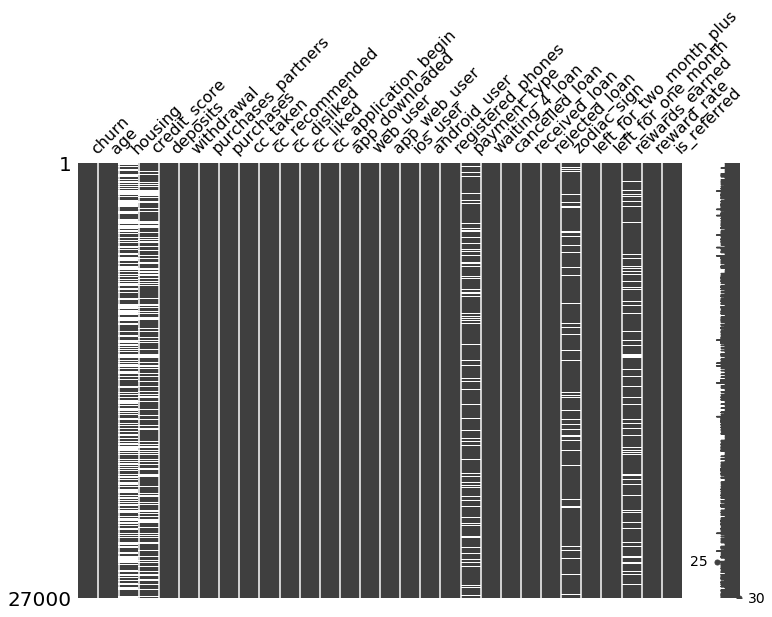

In [76]:
print(churn_data.isna().sum())
missingno.matrix(churn_data,figsize=(12,8))

We can get a clear picture from above that the columns which have white spaces in it contain null values.

### Imputing the missing values

##### For numerical cols , we use 'mean' for imputation.

In [77]:
num_cols = ['age','credit_score','rewards_earned']

churn_data[num_cols] = churn_data[num_cols].fillna(churn_data[num_cols].mean())

##### For categorical cols, we can replace by 'mode'.

In [78]:
# Converting this null values using 'mode'
churn_data[obj_cols] = churn_data[obj_cols].fillna(churn_data[obj_cols].mode().iloc[0])

In [79]:
# Checking for null values after imputation
churn_data.isnull().sum()

churn                      0
age                        0
housing                    0
credit_score               0
deposits                   0
withdrawal                 0
purchases_partners         0
purchases                  0
cc_taken                   0
cc_recommended             0
cc_disliked                0
cc_liked                   0
cc_application_begin       0
app_downloaded             0
web_user                   0
app_web_user               0
ios_user                   0
android_user               0
registered_phones          0
payment_type               0
waiting_4_loan             0
cancelled_loan             0
received_loan              0
rejected_loan              0
zodiac_sign                0
left_for_two_month_plus    0
left_for_one_month         0
rewards_earned             0
reward_rate                0
is_referred                0
dtype: int64

In [80]:
# Getting unique column of each feature
churn_data.nunique()

churn                        2
age                         74
housing                      2
credit_score               460
deposits                    66
withdrawal                  23
purchases_partners         294
purchases                   64
cc_taken                    12
cc_recommended             325
cc_disliked                 20
cc_liked                     9
cc_application_begin       128
app_downloaded               2
web_user                     2
app_web_user                 2
ios_user                     2
android_user                 2
registered_phones            5
payment_type                 4
waiting_4_loan               2
cancelled_loan               2
received_loan                2
rejected_loan                2
zodiac_sign                 12
left_for_two_month_plus      2
left_for_one_month           2
rewards_earned              92
reward_rate                193
is_referred                  2
dtype: int64

We see that feature 'zodiac_sign' is not useful in analysis. Hence, will be dropping the feature.

In [81]:
churn_data = churn_data.drop(['zodiac_sign'],axis=1)

#### Outlier Analysis

In [82]:
cont_var = ['age','credit_score','deposits','withdrawal','purchases_partners','purchases','cc_disliked',
            'cc_liked','cc_application_begin','rewards_earned','reward_rate']

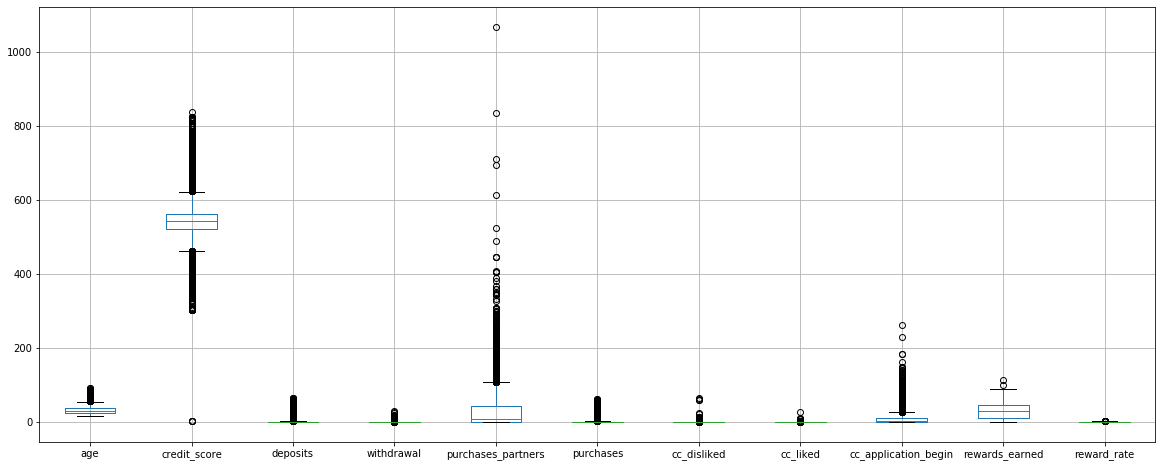

In [83]:
churn_data[cont_var].boxplot(return_type='axes',figsize=(20,8))

In [84]:
for i in cont_var:
    q75, q25 = np.percentile(churn_data.loc[:,i], [75, 25])
    iqr = q75 - q25
    minn = q25 - (iqr*1.5)
    maxx = q75 + (iqr*1.5)
    print('Column Name : ', i)
    print("Min value : ",minn)
    print("Max value : ",maxx)
    print(" ")
    print('# outliers in {var}  ---->{X} Outliers'.format(var=i, X = (churn_data.loc[churn_data.loc[:,i]
                                  < minn, i].count() + churn_data.loc[churn_data.loc[:,i] >
                                                                         maxx, i].count())))

Min value :  7.0
Max value :  55.0
 
age---->838 Outliers
Min value :  462.0
Max value :  622.0
 
credit_score---->3203 Outliers
Min value :  -1.5
Max value :  2.5
 
deposits---->5298 Outliers
Min value :  0.0
Max value :  0.0
 
withdrawal---->4005 Outliers
Min value :  -64.5
Max value :  107.5
 
purchases_partners---->1391 Outliers
Min value :  -1.5
Max value :  2.5
 
purchases---->5258 Outliers
Min value :  0.0
Max value :  0.0
 
cc_disliked---->556 Outliers
Min value :  0.0
Max value :  0.0
 
cc_liked---->230 Outliers
Min value :  -16.5
Max value :  27.5
 
cc_application_begin---->1713 Outliers
Min value :  -40.0
Max value :  96.0
 
rewards_earned---->2 Outliers
Min value :  -1.7950000000000002
Max value :  3.5250000000000004
 
reward_rate---->37 Outliers


If outliers are removed , 60.82% of data will be lost. So, it doesn't seem to be an effective way to use outliers.

### <font color='sky blue'>8. Exploratory Data Analysis(EDA)</font>

Let's us begin our EDA by finding out the proportion of customers being churned or retained by the bank.

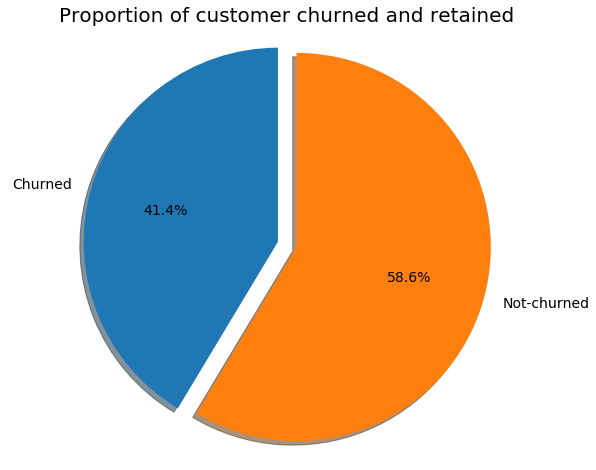

In [85]:
labels = 'Churned','Not-churned'
sizes = [churn_data.churn[churn_data['churn']==1].count(), churn_data.churn[churn_data['churn']==0].count()]
explode = (0, 0.1)
fig, ax = plt.subplots(figsize=(10,8))
ax.pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%', shadow=True, startangle=90, textprops={'fontsize':14})
ax.axis('equal')
plt.title("Proportion of customer churned and retained",size=20)
plt.show()

So about 41.4% of customers are getting churned. We have to ensure that the model which we choose predicts this 41.4% with greater accuracy as the bank has to work on it and retain it's customers who are on the verge of churning.

#### Let us replace the 'churn' column labels to 'churn' and 'No_churn' for analysis

In [86]:
churned_users = {0:'No_churn', 1: 'churn'}

In [87]:
churn_data['churn'] = [churned_users[i] for i in churn_data.churn]

In [88]:
churn_data.head()

,churn,age,housing,credit_score,deposits,withdrawal,purchases_partners,purchases,cc_taken,cc_recommended,cc_disliked,cc_liked,cc_application_begin,app_downloaded,web_user,app_web_user,ios_user,android_user,registered_phones,payment_type,waiting_4_loan,cancelled_loan,received_loan,rejected_loan,left_for_two_month_plus,left_for_one_month,rewards_earned,reward_rate,is_referred
user,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
55409,No_churn,37.0,R,542.944225,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,Bi-Weekly,0,0,0,0,1,0,29.110125,0.00,0
23547,No_churn,28.0,R,486.000000,0,0,1,0,0,96,0,0,5,1,1,1,1,0,0,Weekly,0,0,0,0,0,0,44.000000,1.47,1
58313,No_churn,35.0,R,561.000000,47,2,86,47,0,285,0,0,9,1,0,0,0,1,2,Semi-Monthly,0,0,0,0,1,0,65.000000,2.17,0
8095,No_churn,26.0,R,567.000000,26,3,38,25,0,74,0,0,26,1,0,0,0,1,0,Bi-Weekly,0,0,0,0,0,0,33.000000,1.10,1
61353,churn,27.0,R,542.944225,0,0,2,0,0,0,0,0,0,1,1,1,0,1,0,Bi-Weekly,0,0,0,0,1,0,1.000000,0.03,0


#### Conversion of features 'cc_taken', 'cc_recommended' into categorical features 

##### Column 'cc_taken' 

'cc_taken' indicates the Credit_Cards taken by the customers from the bank 

In [89]:
churn_data['cc_taken'].value_counts()

0     25705
1       923
2       218
3        75
4        45
5        16
6        11
10        2
7         2
29        1
11        1
8         1
Name: cc_taken, dtype: int64

Many customers have not opted for Credit_Cards, but there are customers who have opted for Credit Cards many times. Inorder, to make the understanding better let us categorize it based on frequencies.

In [90]:
# Convert the values in column 'cc_taken' to various categories 
cc_taken_freq=1000
cc=dict(zip(*np.unique(churn_data.cc_taken,return_counts=True)))
churn_data.cc_taken=churn_data.cc_taken.apply(lambda x:'Opted' if cc[x] < cc_taken_freq else 'Not-opted')

In [91]:
churn_data['cc_taken'].value_counts()

Not-opted    25705
Opted         1295
Name: cc_taken, dtype: int64

#### Column 'cc_recommended' 

Credit cards being referred by customers

In [92]:
churn_data['cc_recommended'].value_counts()[:20]
# top 20 value counts

0      3767
5       757
1       440
10      401
6       338
15      318
4       276
20      243
2       232
11      228
3       211
30      200
25      189
9       184
35      178
12      171
8       169
16      162
7       158
40      155
24      152
50      142
45      142
21      139
55      138
18      131
26      131
14      129
17      127
13      119
       ... 
299      23
277      22
301      21
286      20
296      19
278      17
298      17
291      17
302      13
297       9
303       8
306       7
308       7
320       5
309       5
310       3
315       3
307       3
311       2
314       2
312       2
321       2
323       2
313       1
326       1
522       1
324       1
316       1
322       1
318       1
Name: cc_recommended, Length: 325, dtype: int64

In [93]:
cc_recomm_freq=3000
cc_recomm=dict(zip(*np.unique(churn_data.cc_recommended,return_counts=True))) 
churn_data.cc_recommended=churn_data.cc_recommended.apply(lambda x:'Recommended' if cc_recomm[x] < cc_recomm_freq else 'Not-recommended')

In [94]:
churn_data['cc_recommended'].value_counts()

Recommended        23233
Not-recommended     3767
Name: cc_recommended, dtype: int64

#### Column 'registered_phones' 

In [95]:
churn_data['registered_phones'].value_counts()

0    21960
2     4048
3      754
4      183
5       55
Name: registered_phones, dtype: int64

#### Let us categorise the above variable into two different categories:- 'Registered' and 'Not-Registered'

In [96]:
reg_phone_freq=5000
reg_phone = dict(zip(*np.unique(churn_data.registered_phones,return_counts=True)))
churn_data.registered_phones=churn_data.registered_phones.apply(lambda x:'Not-Registered' if reg_phone[x] < reg_phone_freq else 'Registered')

In [97]:
churn_data['registered_phones'].value_counts()

Registered        21960
Not-Registered     5040
Name: registered_phones, dtype: int64

In [98]:
# Converting the features to 'object' data type
cat_cols = ['housing','cc_taken','cc_recommended','app_downloaded','web_user','app_web_user','ios_user','android_user','registered_phones','payment_type','waiting_4_loan','cancelled_loan','received_loan','rejected_loan','left_for_two_month_plus','left_for_one_month','is_referred']
churn_data[cat_cols] = churn_data[cat_cols].astype('object')

In [99]:
churn_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 27000 entries, 55409 to 52752
Data columns (total 29 columns):
churn                      27000 non-null object
age                        27000 non-null float64
housing                    27000 non-null object
credit_score               27000 non-null float64
deposits                   27000 non-null int64
withdrawal                 27000 non-null int64
purchases_partners         27000 non-null int64
purchases                  27000 non-null int64
cc_taken                   27000 non-null object
cc_recommended             27000 non-null object
cc_disliked                27000 non-null int64
cc_liked                   27000 non-null int64
cc_application_begin       27000 non-null int64
app_downloaded             27000 non-null object
web_user                   27000 non-null object
app_web_user               27000 non-null object
ios_user                   27000 non-null object
android_user               27000 non-null object
registered

### <font color='sky blue'>Univariate Analysis</font>

In [100]:
def visualize_plot(df, col_to_exclude, tgt_col, object_mode = True):
    n = 0
    this = []
    
    if object_mode:
        n_rows = 4
        n_cols = 4
        width = 20
        height = 20
    else:
        n_rows = 5
        n_cols = 2
        width = 20
        height = 20
        
    for column in df.columns:
        if object_mode:
            if (df[column].dtypes == 'O') & (column != col_to_exclude):
                this.append(column)
        
        else:
            if (df[column].dtypes != 'O')& (column != tgt_col):
                this.append(column)
                
    
    fig, ax = plt.subplots(n_rows, n_cols, sharex=False, sharey=False, figsize=(width,height))
    for row in range(n_rows):
        for col in range(n_cols):
            if object_mode:
                g = sns.countplot(df[this[n]], ax=ax[row][col])
        
            else:
                g = sns.distplot(df[this[n]], ax=ax[row][col])
        
                
                
            ax[row,col].set_title("Column Name: {}".format(this[n]))
            ax[row,col].set_xlabel("")
            ax[row,col].set_ylabel("")
            n += 1
    
    
    plt.show();
    return 

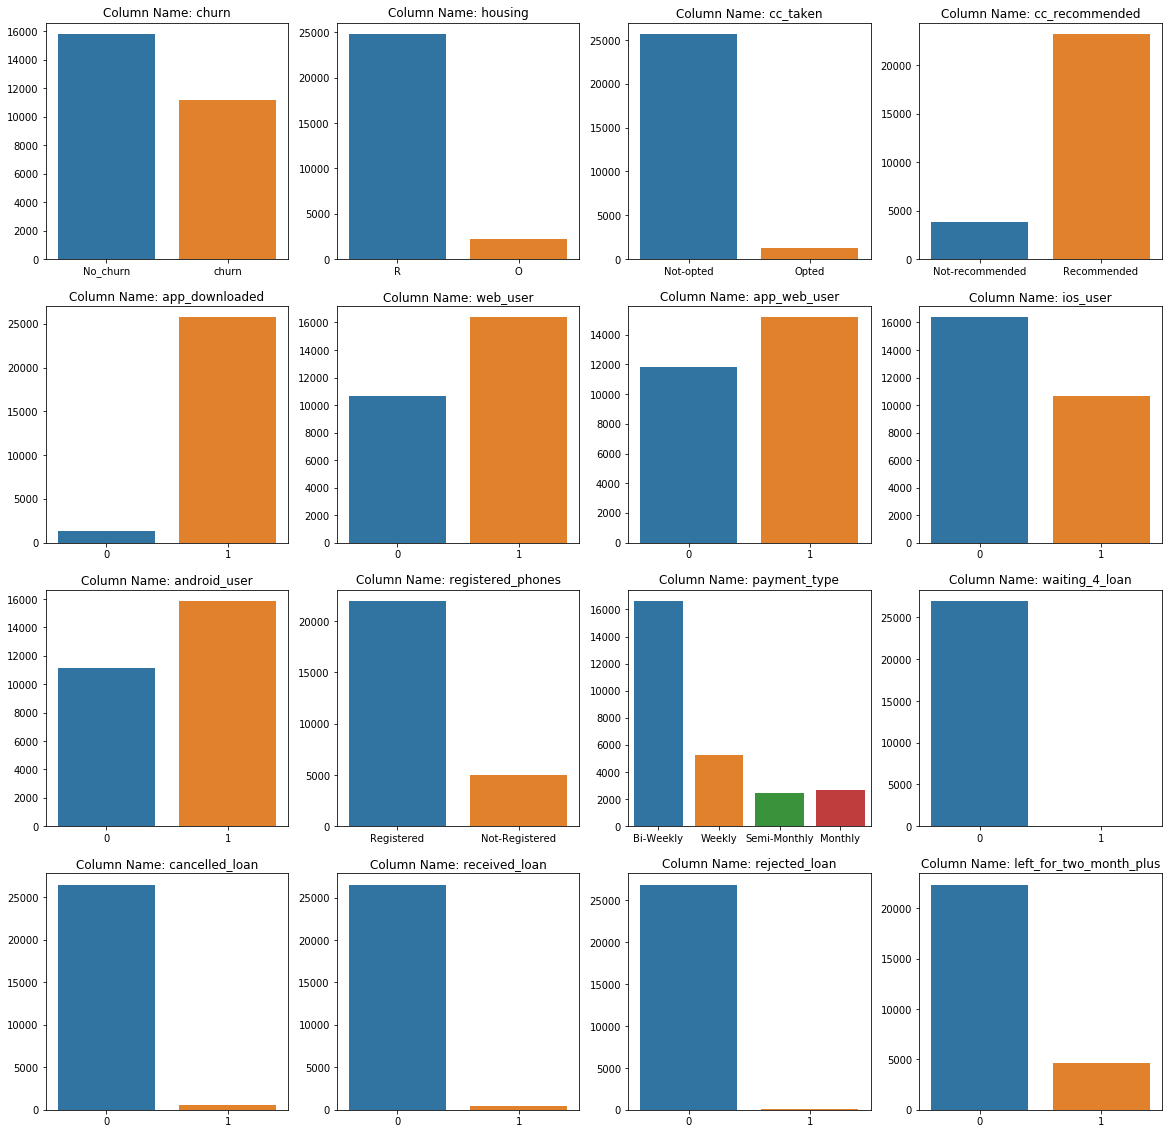

In [101]:
visualize_plot(churn_data,'user','churn',object_mode=True)

##### Insights from the categorical features:-

Most of the customers of the bank reside in rent houses and the credit cards opted by them are quite less.
Well, the credit cards are recommended to them regularly by the bank. Looks like they are prominent users of  online bank portals rather than physically  visiting bank, we can see through their usage of mobile apps, web apps and less use of landline phones. They prefer to pay credit card bills every fortnight. Even though loans are being granted to them without much hiccups, but still some customers aren't happy with the bank and they seem to be inactive for a longer tenure.

C:\Users\Dad\Anaconda3\lib\site-packages\scipy\stats\stats.py:1713: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  return np.add.reduce(sorted[indexer] * weights, axis=axis) / sumval


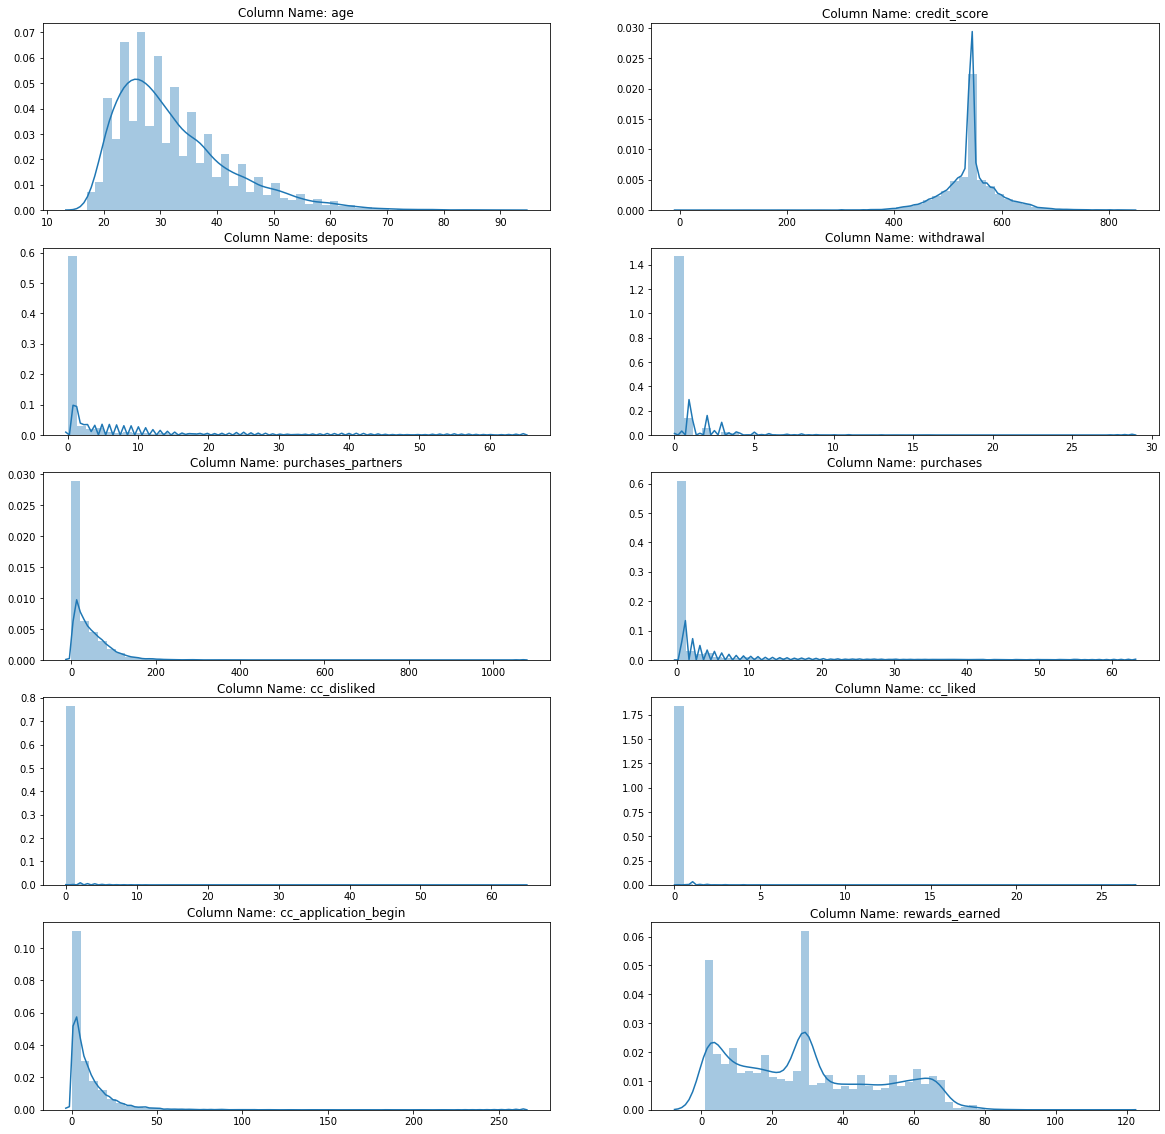

In [102]:
visualize_plot(churn_data,'user','churn',object_mode=False)

In [103]:
churn_data['deposits'].value_counts()

0     18156
1      2461
2      1085
3       679
4       454
5       401
6       328
7       266
8       207
9       193
10      175
11      173
13      134
12      130
14      125
15      117
18      106
17      101
19       99
16       98
20       79
25       67
24       61
28       56
26       52
21       52
22       52
27       50
31       48
37       44
      ...  
32       39
42       38
29       38
36       38
41       38
38       35
44       33
55       32
53       31
40       31
52       29
54       27
57       26
60       26
43       25
48       24
47       24
50       24
56       22
59       20
45       20
58       19
49       18
51       16
46       15
62        7
61        4
64        2
63        2
65        1
Name: deposits, Length: 66, dtype: int64

##### Insights from the continuous variables

When it comes to continuous variables, features seem to be mostly skewed towards right . It means the features have mean greater than the median.

### <font color='sky blue'>Bi-Variate Analysis</font>

In [104]:
def bi_variate(df, col1, col2):
    
    if col2 == 'churn':
        cross_name = pd.crosstab(df[col1], df[col2]).apply(lambda x: x/x.sum() * 100, axis=1)
    else:
        cross_name = pd.crosstab(df[col1], df[col2]).apply(lambda x: x/x.sum() * 100, axis=0)
   # print(cross_name)
    cross_name.plot.bar()
    plt.xlabel('{}'.format(col1))
    plt.ylabel('% of churn rate')
    plt.title('{} Vs churn'.format(col1))
    plt.xticks(rotation=0)
    plt.figure(figsize=(16,12))
    plt.show()
    return cross_name

#### Housing Vs churn

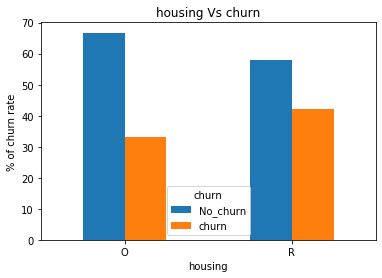

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
housing,,
O,66.743436,33.256564
R,57.904064,42.095936


In [105]:
bi_variate(churn_data, 'housing', 'churn')

On observation of graph, we can infer that Rental housing customer have higher churn rate . Since, rental customers would need a loan to buy own house. If they are satisfied with another bank they might get switched. Also, rental customers have more probability of shifting locations, so they might prefer banks which is near to their location. That also might be the reason for churn of rental customers.

#### cc_taken Vs churn

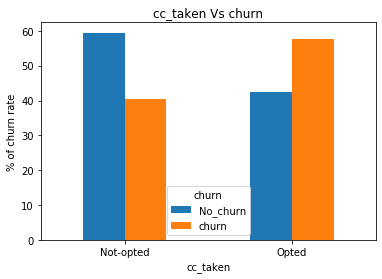

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
cc_taken,,
Not-opted,59.435907,40.564093
Opted,42.316602,57.683398


In [106]:
bi_variate(churn_data, 'cc_taken', 'churn')

From analysis we come to know that 57.68% of customers are getting churned who have for credit card. The customers might not be able to repay their credit loans or interest rates might have rised up, also their might be possibility of customers becoming unemployed without any prior knowledge or better credit card from other bank might lead to change in bank account as well. 

#### cc_recommended Vs churn

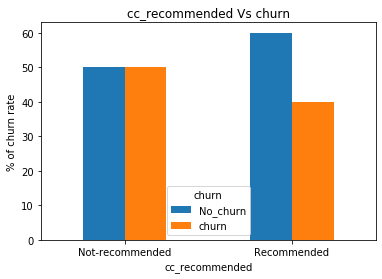

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
cc_recommended,,
Not-recommended,49.986727,50.013273
Recommended,60.013774,39.986226


In [107]:
bi_variate(churn_data, 'cc_recommended','churn')

We see that customers getting recommended for credit cards and getting churned is about 40%. So , bank needs to work on various strategies while referring credit cards to customers.

#### payment_type Vs churn

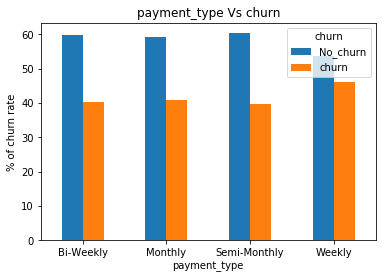

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
payment_type,,
Bi-Weekly,59.795366,40.204634
Monthly,59.224398,40.775602
Semi-Monthly,60.327869,39.672131
Weekly,53.809794,46.190206


In [108]:
bi_variate(churn_data, 'payment_type','churn')
# round to 2 digits

From the above graphs we infer that, customers who are paying their credit cards Bi-Weekly and Weekly are the most. Also, they are the ones who are getting churned the highest. It might be due to the offers or interest rate they may find in other banks.

#### cancelled_loan Vs churn

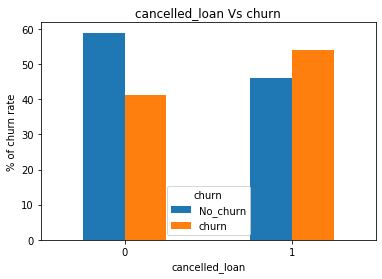

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
cancelled_loan,,
0,58.855504,41.144496
1,46.062992,53.937008


In [109]:
bi_variate(churn_data,'cancelled_loan','churn')

The high orange bar only says it, the customers loan getting cancelled are the most getting churned.

#### received_loan Vs churn

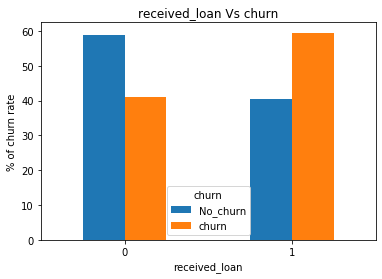

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
received_loan,,
0,58.949791,41.050209
1,40.529532,59.470468


In [110]:
bi_variate(churn_data, 'received_loan','churn')

Customers who are receiving loans are getting churned. It might be due to repayment of loans, high-interest rates charged by banks.

#### rejected_loan Vs churn

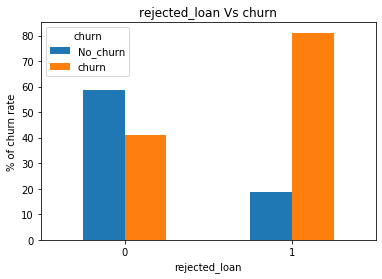

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
rejected_loan,,
0,58.809736,41.190264
1,18.939394,81.060606


In [111]:
bi_variate(churn_data, 'rejected_loan','churn')

Above observation shows us that, rejection of loan in customers has maximum churn rate. Out of coursity , let us see how it would be for waiting_4_loan customers.

#### waiting_4_loan vs churn

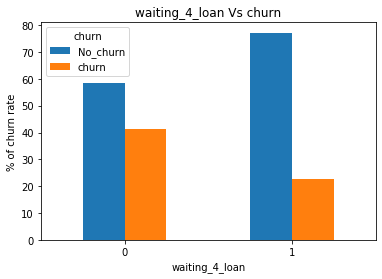

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
waiting_4_loan,,
0,58.590766,41.409234
1,77.142857,22.857143


In [112]:
bi_variate(churn_data,'waiting_4_loan','churn')

Customers waiting_4_loan and churning is fine. But, customers not waiting_4_loan and getting churned is an alarming situation. Bank need to analyse this scenario.

#### Let us now analyse the other aspects for customer churn (mobile/web) applications

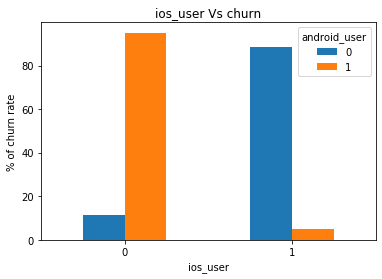

<Figure size 1152x864 with 0 Axes>

android_user,0,1
ios_user,,
0,11.647523,95.017659
1,88.352477,4.982341


In [113]:
bi_variate(churn_data,'ios_user','android_user')

Usage of Android phones is more compare to ios phones by customers. Bank can comeup with new mobile-friendly usage of applications to these users.

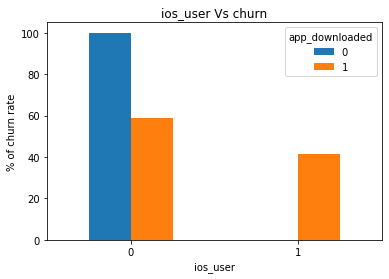

<Figure size 1152x864 with 0 Axes>

app_downloaded,0,1
ios_user,,
0,100.0,58.642143
1,0.0,41.357857


In [114]:
# How many have downloaded apps among ios and android phones
# Let us first find for ios_users
bi_variate(churn_data,'ios_user','app_downloaded')

So we can say that android users have mostly downloaded the bank's apps in their mobiles. Android allows easy accessible to apps with no much restriction, that is why android users are far better in using apps than ios_users.

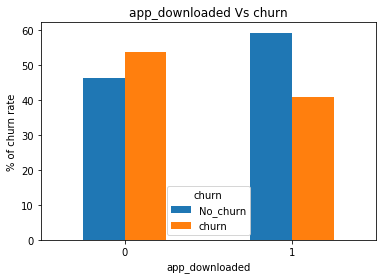

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
app_downloaded,,
0,46.375682,53.624318
1,59.225415,40.774585


In [115]:
# let us compare the app's downloaded to the churn of customer from bank
bi_variate(churn_data, 'app_downloaded','churn')

Customers who are not using the bank apps are getting churned the most, since they may be not using the features, much help to them may not be reached instantly so finding hindrance in reaching out to banks. Also, it can be acute information about the latest bank updates and policies to them , which will be easily notified through bank apps.

Now we will see the customer churn in case of app_web_user.

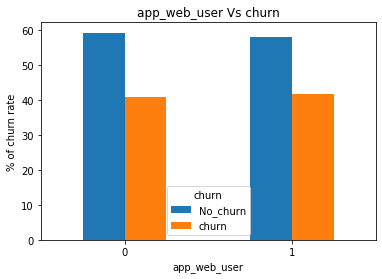

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
app_web_user,,
0,59.241105,40.758895
1,58.126195,41.873805


In [116]:
# Comparison of app_web_user Vs churn
bi_variate(churn_data,'app_web_user','churn')

There is slight difference in churn rate, among customers using app_web and not using app_web.

#### web_user Vs churn

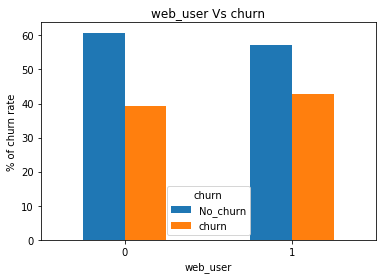

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
web_user,,
0,60.765325,39.234675
1,57.217062,42.782938


In [117]:
bi_variate(churn_data,'web_user','churn')

There is not much variation among web_users and non-web_users getting churned.

#### left_for_two_month_plus Vs left_for_one_month

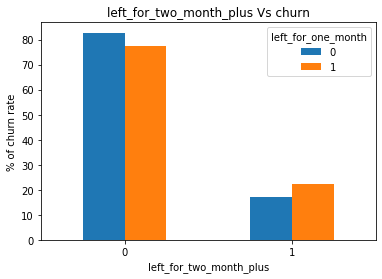

<Figure size 1152x864 with 0 Axes>

left_for_one_month,0,1
left_for_two_month_plus,,
0,82.747435,77.663934
1,17.252565,22.336066


In [118]:
bi_variate(churn_data, 'left_for_two_month_plus','left_for_one_month')

We can observe that 77% customers have left for one month. Let us see how is it impacting the churn.

#### left_for_one_month Vs churn

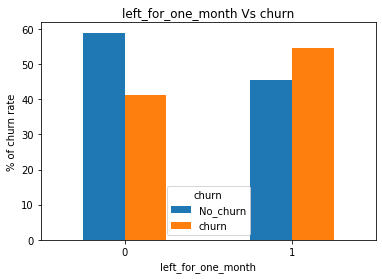

<Figure size 1152x864 with 0 Axes>

churn,No_churn,churn
left_for_one_month,,
0,58.856367,41.143633
1,45.491803,54.508197


In [119]:
bi_variate(churn_data ,'left_for_one_month','churn')

Customers who have left_for_one_month and are getting churned because they are not satisfied with the services they are expecting from the bank. They may be satisfied with the schemes offered by other banks .

Let us explore the numerical features of the dataset, using a correlation matrix.

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5]),
 <a list of 11 Text xticklabel objects>)

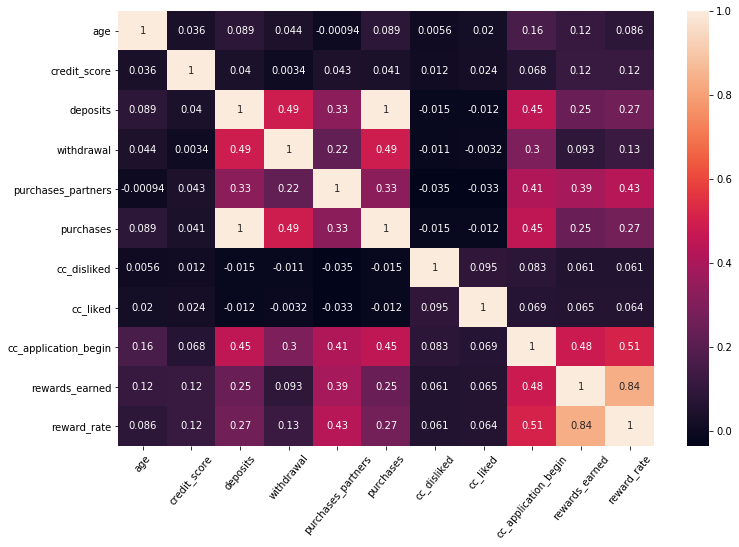

In [120]:
# correlation matrix in seaborn

plt.figure(figsize=(12,8))
sns.heatmap(churn_data.corr(),xticklabels=churn_data.corr().columns.values, yticklabels=churn_data.corr().columns.values, annot=True);
plt.xticks(rotation=50)

'Purchases' and 'Deposits' are highly correlated to each other. Also, there is a strong correlation between 'rewards_earned' and 'rewards_rate'. We can say that, Value of one point = rewards_rate/ rewards_earned. 

#### Relation of continuous variables with the target feature 'churn'

In [121]:
# Let us convert again target column 'churn' to 0's and 1's inorder to perform comparison with continuous variables

churn_str = {"No_churn" : 0, "churn" :1 }
churn_data['churn'] = churn_data['churn'].map(churn_str)

In [122]:
churn_data.head()

,churn,age,housing,credit_score,deposits,withdrawal,purchases_partners,purchases,cc_taken,cc_recommended,cc_disliked,cc_liked,cc_application_begin,app_downloaded,web_user,app_web_user,ios_user,android_user,registered_phones,payment_type,waiting_4_loan,cancelled_loan,received_loan,rejected_loan,left_for_two_month_plus,left_for_one_month,rewards_earned,reward_rate,is_referred
user,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
55409,0,37.0,R,542.944225,0,0,0,0,Not-opted,Not-recommended,0,0,0,1,1,1,1,0,Registered,Bi-Weekly,0,0,0,0,1,0,29.110125,0.00,0
23547,0,28.0,R,486.000000,0,0,1,0,Not-opted,Recommended,0,0,5,1,1,1,1,0,Registered,Weekly,0,0,0,0,0,0,44.000000,1.47,1
58313,0,35.0,R,561.000000,47,2,86,47,Not-opted,Recommended,0,0,9,1,0,0,0,1,Not-Registered,Semi-Monthly,0,0,0,0,1,0,65.000000,2.17,0
8095,0,26.0,R,567.000000,26,3,38,25,Not-opted,Recommended,0,0,26,1,0,0,0,1,Registered,Bi-Weekly,0,0,0,0,0,0,33.000000,1.10,1
61353,1,27.0,R,542.944225,0,0,2,0,Not-opted,Not-recommended,0,0,0,1,1,1,0,1,Registered,Bi-Weekly,0,0,0,0,1,0,1.000000,0.03,0


#### DataFrame consisting of Continuous variables for further EDA

In [123]:
churn_data_cont = churn_data.select_dtypes([np.int64, np.float64])

In [124]:
churn_data_cont.head()

,churn,age,credit_score,deposits,withdrawal,purchases_partners,purchases,cc_disliked,cc_liked,cc_application_begin,rewards_earned,reward_rate
user,,,,,,,,,,,,
55409,0,37.0,542.944225,0,0,0,0,0,0,0,29.110125,0.00
23547,0,28.0,486.000000,0,0,1,0,0,0,5,44.000000,1.47
58313,0,35.0,561.000000,47,2,86,47,0,0,9,65.000000,2.17
8095,0,26.0,567.000000,26,3,38,25,0,0,26,33.000000,1.10
61353,1,27.0,542.944225,0,0,2,0,0,0,0,1.000000,0.03


#### Finding the distributions of continuous variables w.r.t target

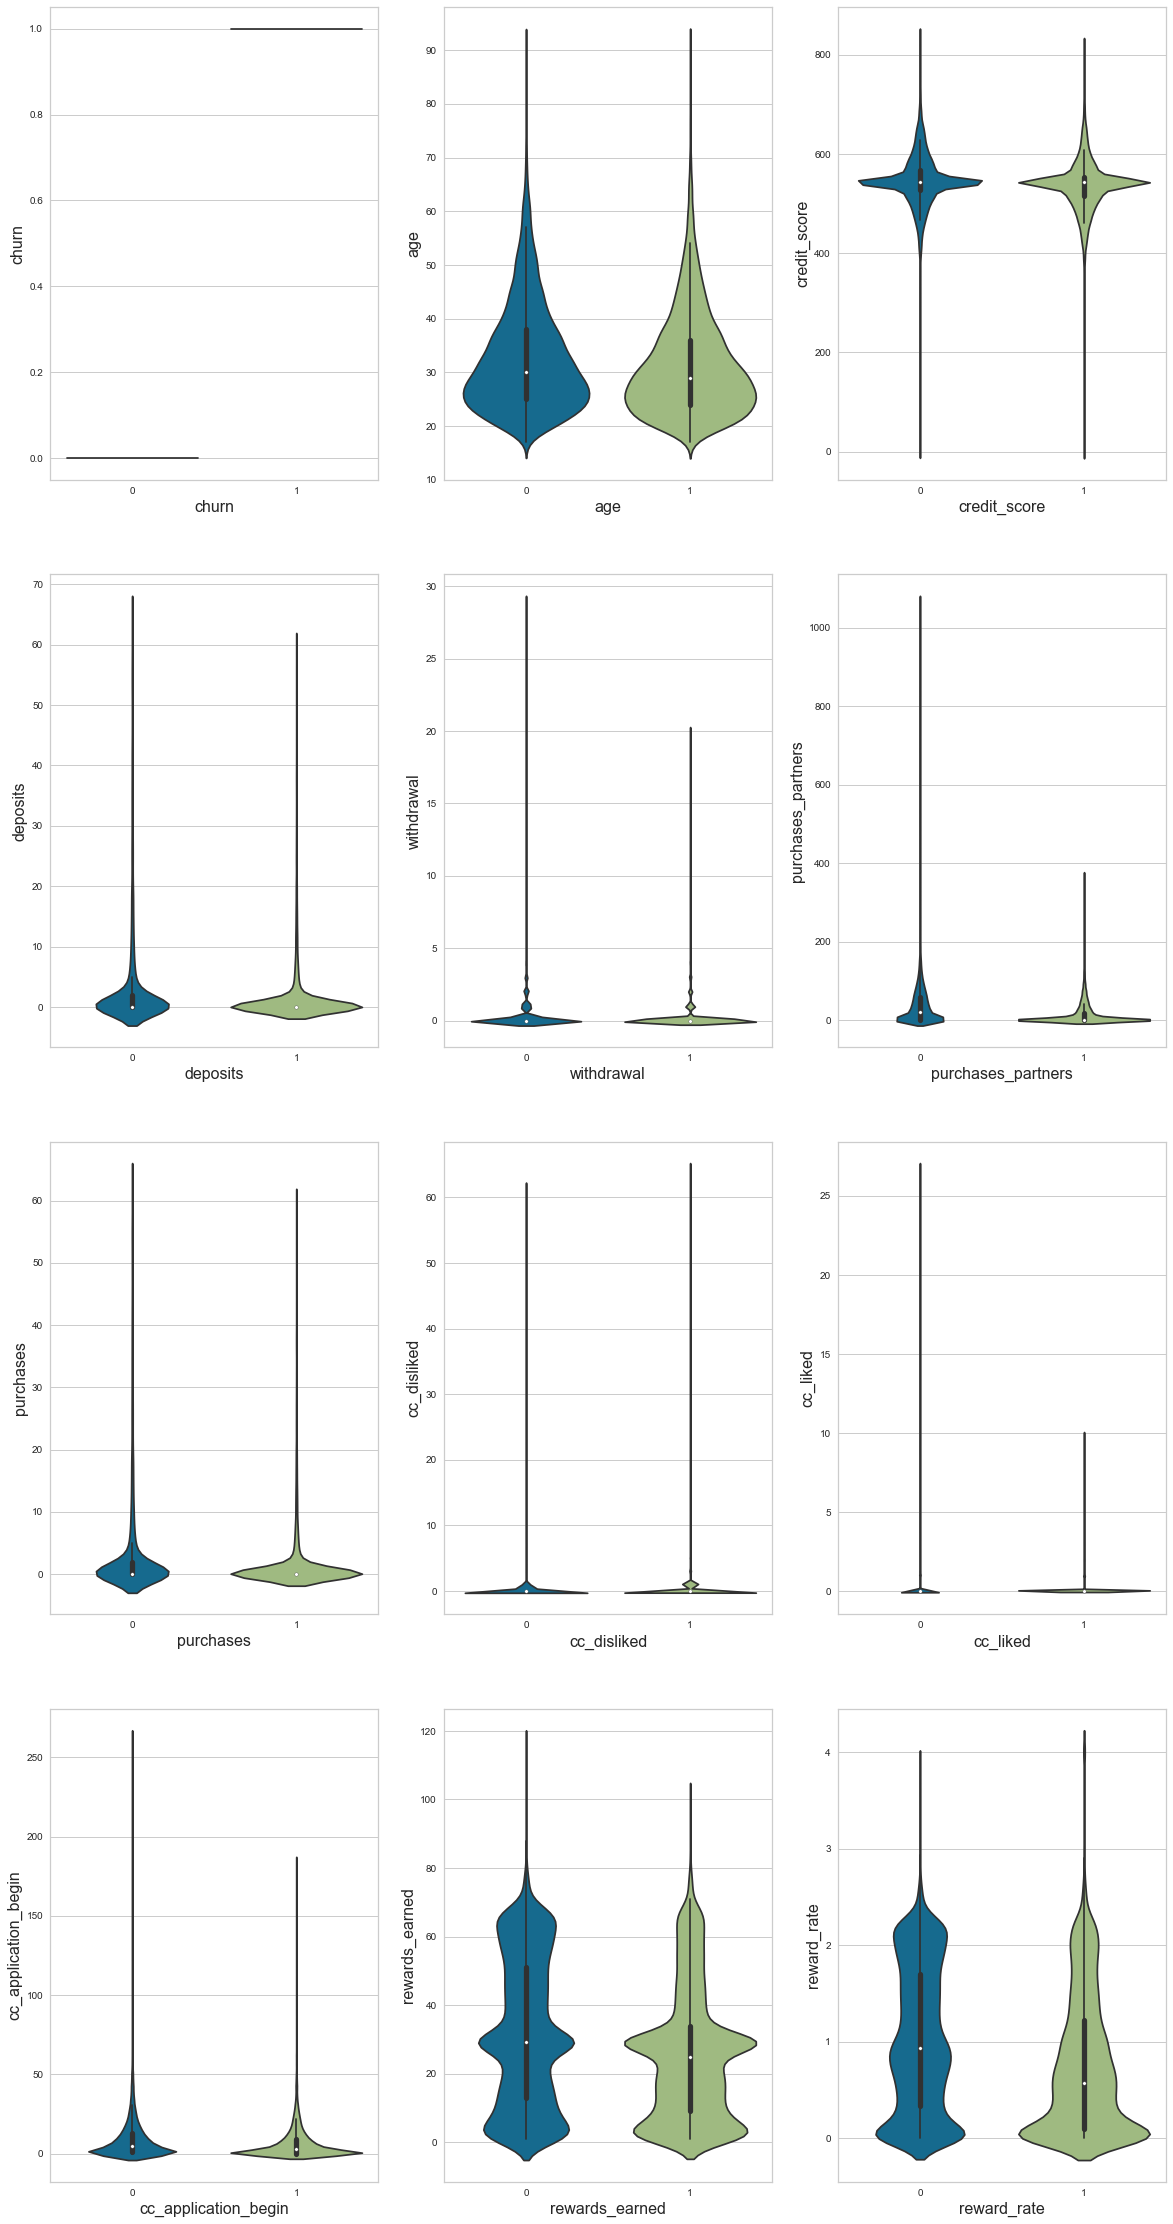

In [336]:
nrows=4
ncols=3
this = []
n = 0

for column in churn_data_cont.columns:
       this.append(column)
        
fig, ax = plt.subplots(nrows,ncols, figsize=(20,40))
for row in range(nrows):
    for col in range(ncols):
        g = sns.violinplot(y=this[n], x='churn',data=churn_data_cont,ax=ax[row][col])
        
        ax[row][col].set_xlabel(this[n],fontsize=16)
        ax[row][col].set_ylabel(this[n],fontsize=16)
        n += 1
    
        
        
    


##### Summary of the above observation:-

- For comparing the churned and unchurned distributions in continuous variables , violin plots seem to be very insightful. Hence, we have used it for our plotting. 

- From figure we can see that violin plots are corresponding to two different distribution[churned and unchurned].

- Interestingly, the mean of the unchurned is higher than the median , it means there are outliers which are pulling the value up in columns such as 'age', 'deposits','cc_application_begin' and so on...

- While in some columns like 'withdrawal','credit_score' distributions are almost the same among churned data and unchurned data.

##### Correlation between Age and Credit_Score

In [172]:
np.corrcoef(churn_data.credit_score, churn_data.age)

array([[1.        , 0.03559663],
       [0.03559663, 1.        ]])

We are not able to observe much correlation between the two.

##### Correlation between Age and Payment_Type

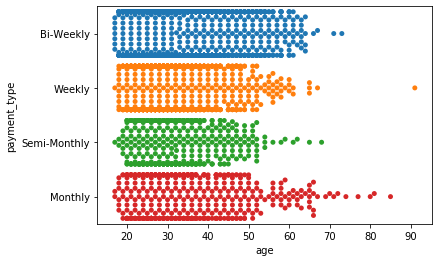

In [173]:
sns.swarmplot(x="age", y="payment_type", data=churn_data[0:5000])

Patterns from the above plot:-
    
- Age group less than 20 are mostly preferring the Bi-Weekly and Weekly payment types[After shopping is done, want to payoff their credit card bills]

- Age group [20-50] are preferring all types of payments. There is no such insights we can find out of it.

- Senior citizen are mostly preferring the Monthly payment. Again, they are tuned to switching on their old styles of payments.

##### Correlation between Credit_score Vs Rewards_earned

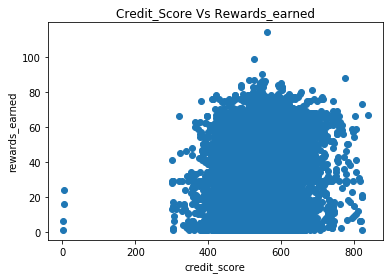

In [174]:
plt.plot('credit_score','rewards_earned', data=churn_data, linestyle='none', marker='o')
plt.xlabel('credit_score')
plt.ylabel('rewards_earned')
plt.title('Credit_Score Vs Rewards_earned')
plt.show()

- Customers with low credit score are still getting rewards more than 20. This can't be the case, it might be wrong data being entered here.
- Customers having score in range of 500-600 are having reward points more than 100, while customers having good ranging between 700-750 have rewards_earned about 80-85. 
- Most of the customers have credit score ranging from 400-700 and rewards earned in the range 0-80.

##### Relation between deposits Vs Credit_Card recommendation

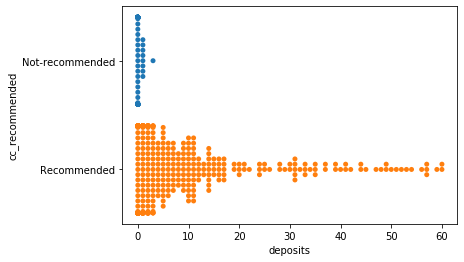

In [175]:
sns.swarmplot(x="deposits", y="cc_recommended", data=churn_data[0:1000])

Customers who have deposits ranging from 0-10 are recommended for Credit Cards, and customers who have almost nil deposits are not recommended for credit cards.

Upon understanding the patterns in the data, it is time for us to build a model. 

### <font color='sky blue'> 9. Feature Enginnering</font>

We will capture credit_score given age into account credit behaviour

In [176]:
churn_data['Credit_ScoreGivenAge'] = churn_data.credit_score / (churn_data.age)

In [177]:
churn_data['Credit_ScoreGivenAge']

user
55409    14.674168
23547    17.357143
58313    16.028571
8095     21.807692
61353    20.109045
3120     17.718750
41406    22.619048
67679    22.622676
21269    19.571429
25788    28.608696
13840    16.967007
25899    15.243902
20839    27.500000
13019    21.000000
24387    11.552005
65427    12.339641
30419    19.958333
30693    18.225806
69531    27.147211
34733    18.098141
66712     9.202444
15359    30.333333
25997    16.945946
13813    16.833333
67807    15.081784
19184    12.522727
34210     9.961538
57598    21.160000
57608    23.090909
8381     14.288006
           ...    
12588    26.454545
67090    21.717769
53666    22.622676
31403    21.717769
47206    21.461538
63394    16.967007
28036    10.057692
15756    28.272727
22955    10.054523
65004    16.878788
67182    16.452855
4109     11.311338
52358    14.026316
68179    15.968948
57660    22.880000
19540    23.606271
22377    14.857143
47156    28.043478
39792    22.622676
24442    19.064516
32870    20.103448
49367  

Another feature which we tried to figure out is Rewards_Ratio = Rewards_earned / Reward_Rate.

In [178]:
churn_data['value_of_one_point'] = churn_data.reward_rate / (churn_data.rewards_earned)

In [179]:
churn_data['value_of_one_point']

user
55409    0.000000
23547    0.033409
58313    0.033385
8095     0.033333
61353    0.030000
3120     0.033273
41406    0.035000
67679    0.110000
21269    0.033462
25788    0.033437
13840    0.043684
25899    0.033385
20839    0.033333
13019    0.033333
24387    0.062727
65427    0.035000
30419    0.033333
30693    0.033256
69531    0.000000
34733    0.035000
66712    0.000000
15359    0.000000
25997    0.033250
13813    0.033333
67807    0.500000
19184    0.034000
34210    0.033333
57598    0.033571
57608    0.033333
8381     0.125000
           ...   
12588    0.033243
67090    0.000000
53666    0.030000
31403    0.033333
47206    0.033333
63394    0.000000
28036    0.033279
15756    0.033333
22955    0.033265
65004    0.500000
67182    0.000000
4109     0.033077
52358    0.033158
68179    0.000000
57660    0.033333
19540    0.033333
22377    0.033409
47156    0.033437
39792    0.033333
24442    0.033265
32870    0.033437
49367    0.030000
65830    0.032500
41813    0.030000
49903

### <font color='sky blue'> 10. Data Preprocessing</font>

### <font color = 'sky blue'> Encoding categorical variable</font>

In [180]:
from sklearn.preprocessing import LabelEncoder

# user id col
Id_col = ['user']
# Target cols
tgt_col = ['churn']

# Categorical cols
category_cols = churn_data.nunique()[churn_data.nunique() < 6].keys().tolist()
category_cols = [ x for x in category_cols if x not in tgt_col]

# num_cols
num_cols = [x for x in num_cols if x not in category_cols+tgt_col+Id_col]

# bin_cols
bin_cols = churn_data.nunique()[churn_data.nunique() == 2].keys().tolist()

# multi-cols(more than 2 values)
multi_cols = [i for i in category_cols if i not in bin_cols]

# Label encoding Binary cols
le = LabelEncoder()
for i in bin_cols:
    churn_data[i] = le.fit_transform(churn_data[i])
    
# Duplicating columns for multi-value columns
churn_data = pd.get_dummies(data=churn_data,columns=multi_cols)


### <font color='sky blue'>Normalizing features</font>

In [181]:
bank = churn_data
# Scaling Numerical cols
from sklearn.preprocessing import StandardScaler

std = StandardScaler()
scaled = std.fit_transform(bank[num_cols])
scaled = pd.DataFrame(scaled, columns=num_cols)

# Dropping original values merging scaled values for numerical cols
data_bank = bank.copy()
bank = bank.drop(columns=num_cols, axis=1)
bank = bank.merge(scaled,left_index=True,right_index=True,how='left')

### <font color = 'sky blue'>Train/val/Test split</font>

In [182]:
from sklearn.model_selection import train_test_split

In [183]:
bank = churn_data

# Train test split
train, test = train_test_split(bank, test_size=0.3, random_state = 0)

# Seperating dependent and independent variables
cols = [ i for i in bank.columns if i not in tgt_col]
X_train = train[cols]
Y_train = train['churn']
X_test = test[cols]
Y_test = test['churn']

### <font color = 'sky blue'> 11. Model Building </font>

#### <font color='sky blue'>Baseline Model</font>

In [209]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.metrics import roc_auc_score, roc_curve, scorer
from sklearn.metrics import f1_score
import statsmodels.api as sm
from sklearn.metrics import precision_score, recall_score
from yellowbrick.classifier import DiscriminationThreshold
import plotly.offline as py#visualization
py.init_notebook_mode(connected=True)#visualization
import plotly.plotly as ply
import plotly.graph_objs as go#visualization
import plotly.tools as tls#visualization
import plotly.figure_factory as ff#visualization

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
          intercept_scaling=1, max_iter=100, multi_class='ovr', n_jobs=1,
          penalty='l2', random_state=None, solver='liblinear', tol=0.0001,
          verbose=0, warm_start=False)
Classification Report : 
               precision    recall  f1-score   support

           0       0.68      0.77      0.72      4733
           1       0.60      0.49      0.54      3367

   micro avg       0.65      0.65      0.65      8100
   macro avg       0.64      0.63      0.63      8100
weighted avg       0.65      0.65      0.65      8100

Accuracy Score :  0.6541975308641975
 Area under curve :  0.6306815739522269 

This is the format of your plot grid:
[ (1,1) x1,y1 ]  [ (1,2) x2,y2 ]
[ (2,1) x3,y3           -      ]



C:\Users\Dad\Anaconda3\lib\site-packages\plotly\offline\offline.py:524: UserWarning:

Your filename `Machine Learning_algos` didn't end with .html. Adding .html to the end of your file.



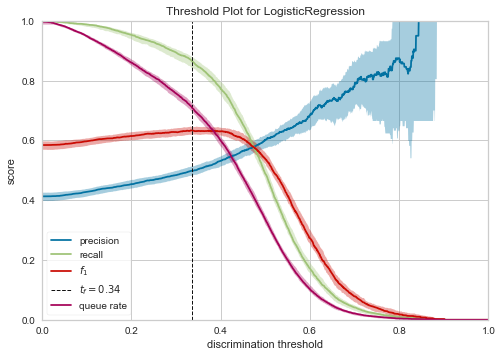

In [220]:
def bank_churn_prediction(algorithm, train_x, test_x, train_y, test_y, cols, cf,threshold_plot):
    # model
    algorithm.fit(train_x, train_y)
    predictions = algorithm.predict(test_x)
    probabilites = algorithm.predict_proba(test_x)
    # coeffs
    if cf == 'coefficients':
        coefficients = pd.DataFrame(algorithm.coef_.ravel())
    elif cf == 'features':
        coefficients = pd.DataFrame(algorithm.feature_importances_)
        
    column_df = pd.DataFrame(cols)
    coef_summary = (pd.merge(coefficients, column_df, left_index=True, right_index=True, how='left'))
    coef_summary.columns = ["coefficients","features"]
    coef_summary = coef_summary.sort_values(by = "coefficients",ascending = False)
    
    print(algorithm)
    print("Classification Report : \n",classification_report(test_y, predictions))
    print("Accuracy Score : ", accuracy_score(test_y, predictions))
    
    # confusion matrix
    conf_matrix = confusion_matrix(test_y, predictions)
    
    # roc_auc_score
    model_roc_auc = roc_auc_score(test_y, predictions)
    print(" Area under curve : ",model_roc_auc,"\n")
    fpr, tpr, thresholds = roc_curve(test_y, probabilites[:,1])
    
    # Plot confusion matrix
    trace1 = go.Heatmap(z = conf_matrix,
                          x = ["Not churn","Churn"],
                          y = ["Not churn","Churn"],
                          showscale = False, colorscale = 'Picnic',
                          name = "matrix")
    
    # Plot roc_curve
    trace2 = go.Scatter(x = fpr, y = tpr, 
                        name = "Roc curve: "+ str(model_roc_auc),
                        line = dict(color=('rgb(22, 96, 167)'),width = 2))
    
    trace3 = go.Scatter(x = [0,1], y = [0,1],
                        line = dict(color = ('rgb(205, 12, 24)'), width = 2, dash = 'dot' ))
                        
                          
    # Plot coefficients
    trace4 = go.Bar(x = coef_summary["features"], y = coef_summary["coefficients"],
                    name = "coefficients",
                    marker = dict(color = coef_summary['coefficients'],
                                  colorscale = "Picnic",
                                  line = dict(width = .6, color = 'black')))
    
    # subplots 
    fig = tls.make_subplots(rows=2, cols=2, specs=[[{}, {}], [{'colspan': 2}, None]],
                            subplot_titles=('Confusion Matrix',
                                            'Receiver operating characteristic',
                                            'Feature Importances'))
    
    fig.append_trace(trace1,1,1)
    fig.append_trace(trace2,1,2)
    fig.append_trace(trace3,1,2)
    fig.append_trace(trace4,2,1)
    
    fig['layout'].update(showlegend=False, title="Model performance" ,
                         autosize = False,height = 900,width = 800,
                         plot_bgcolor = 'rgba(240,240,240, 0.95)',
                         paper_bgcolor = 'rgba(240,240,240, 0.95)',
                         margin = dict(b = 195))
    fig["layout"]["xaxis2"].update(dict(title = "false positive rate"))
    fig["layout"]["yaxis2"].update(dict(title = "true positive rate"))
    fig["layout"]["xaxis3"].update(dict(showgrid = True,tickfont = dict(size = 10),
                                        tickangle = 90))
    url = py.plot(fig,filename="Machine Learning_algos")
    
    
    if threshold_plot == True : 
        visualizer = DiscriminationThreshold(algorithm)
        visualizer.fit(train_x,train_y)
        visualizer.poof()
                        

logit  = LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
          intercept_scaling=1, max_iter=100, multi_class='ovr', n_jobs=1,
          penalty='l2', random_state=None, solver='liblinear', tol=0.0001,
          verbose=0, warm_start=False)


bank_churn_prediction(logit, X_train, X_test, Y_train, Y_test, cols, "coefficients", threshold_plot = True)
    
#py.iplot(bank_churn_prediction(logit, X_train, X_test, Y_train, Y_test, cols, "coefficients", threshold_plot = True), filename='log_reg',auto_open=False)
    

#### <font color='sky blue'>Synthetic Minority Oversampling Technique</font>

<ul>
<li> Randomly pick a point from the minority class</li>
<li> Compute the k-nearest neighors for this point</li>
<li> Add k new points between the choosen point and it's neighbors </li>
</ul>

In [221]:
from imblearn.over_sampling import SMOTE

In [222]:
cols = [i for i in bank.columns if i not in Id_col+tgt_col]

smote_X = bank[cols]
smote_Y = bank[tgt_col]

In [223]:
smote_train_X, smote_test_X, smote_train_Y, smote_test_Y = train_test_split(smote_X, smote_Y, test_size=0.25, random_state = 111)

In [224]:
os = SMOTE(random_state = 0)
os_smote_X , os_smote_Y = os.fit_sample(smote_train_X, smote_train_Y)
os_smote_X = pd.DataFrame(data = os_smote_X, columns=cols)
os_smote_Y = pd.DataFrame(data = os_smote_Y, columns=tgt_col)

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



In [225]:
logit_smote = LogisticRegression(C=1.0, class_weight=None,dual=False, fit_intercept=True, 
                                 intercept_scaling=1, max_iter=100, multi_class='ovr',n_jobs=1,
                                 penalty='l2',random_state=None, solver='liblinear',tol=0.0001,
                                 verbose=0, warm_start=False)

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
          intercept_scaling=1, max_iter=100, multi_class='ovr', n_jobs=1,
          penalty='l2', random_state=None, solver='liblinear', tol=0.0001,
          verbose=0, warm_start=False)
Classification Report : 
               precision    recall  f1-score   support

           0       0.74      0.55      0.63      4733
           1       0.54      0.73      0.62      3367

   micro avg       0.63      0.63      0.63      8100
   macro avg       0.64      0.64      0.63      8100
weighted avg       0.66      0.63      0.63      8100

Accuracy Score :  0.6253086419753087
 Area under curve :  0.6409772495764468 

This is the format of your plot grid:
[ (1,1) x1,y1 ]  [ (1,2) x2,y2 ]
[ (2,1) x3,y3           -      ]



C:\Users\Dad\Anaconda3\lib\site-packages\plotly\offline\offline.py:524: UserWarning:

Your filename `Machine Learning_algos` didn't end with .html. Adding .html to the end of your file.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y w

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761

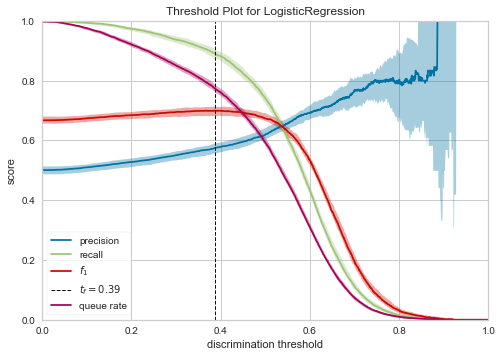

In [226]:
bank_churn_prediction(logit_smote,os_smote_X, X_test, os_smote_Y, Y_test, cols, "coefficients",threshold_plot=True)

#### <font color='sky blue'>Recursive Feature Elimination</font>

It is based on the idea to repeatedly construct a model and choose either the best or worst performing feature, setting the feature aside and repeating the process with rest other features.This is applied until all features are exhausted. The goal of RFE is to select features by recusively considering smaller and smaller sets of features.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning:

Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning:

Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning:

Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning:

Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning:

Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\linear

LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
          intercept_scaling=1, max_iter=100, multi_class='ovr', n_jobs=1,
          penalty='l2', random_state=None, solver='liblinear', tol=0.0001,
          verbose=0, warm_start=False)
Classification Report : 
               precision    recall  f1-score   support

           0       0.69      0.54      0.61      4733
           1       0.50      0.65      0.57      3367

   micro avg       0.59      0.59      0.59      8100
   macro avg       0.60      0.60      0.59      8100
weighted avg       0.61      0.59      0.59      8100

Accuracy Score :  0.5888888888888889
 Area under curve :  0.5980268838920857 

This is the format of your plot grid:
[ (1,1) x1,y1 ]  [ (1,2) x2,y2 ]
[ (2,1) x3,y3           -      ]



C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761

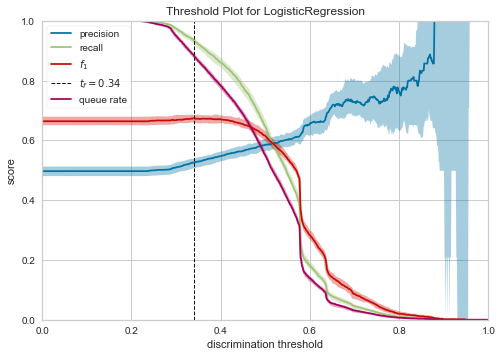

In [84]:
from sklearn.feature_selection import RFE

logit = LogisticRegression()

rfe = RFE(logit,10)
rfe = rfe.fit(os_smote_X,os_smote_Y.values.ravel())

rfe.support_
rfe.ranking_

#identified columns Recursive Feature Elimination
idc_rfe = pd.DataFrame({"rfe_support" :rfe.support_,
                       "columns" : [i for i in bank.columns if i not in Id_col + tgt_col],
                       "ranking" : rfe.ranking_,
                      })
cols = idc_rfe[idc_rfe["rfe_support"] == True]["columns"].tolist()


#separating train and test data
train_rf_X = os_smote_X[cols]
train_rf_Y = os_smote_Y
test_rf_X  = test[cols]
test_rf_Y  = test[tgt_col]

logit_rfe = LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
          intercept_scaling=1, max_iter=100, multi_class='ovr', n_jobs=1,
          penalty='l2', random_state=None, solver='liblinear', tol=0.0001,
          verbose=0, warm_start=False)

#applying model
bank_churn_prediction(logit_rfe,train_rf_X,test_rf_X,train_rf_Y,test_rf_Y,
                         cols,"coefficients",threshold_plot = True)

tab_rk = ff.create_table(idc_rfe)
py.iplot(tab_rk)

#### <font color='sky blue'>Univariate Feature Selection</font>

<ul>
<li>Feature Extraction with Univariate Statistical Tests(Chi-squared for classification)</li>
<li>Uses the chi-squared(chi^2) statistical test for non-negative features to select the best features</li>
</ul>


In [85]:
from sklearn.feature_selection import chi2
from sklearn.feature_selection import SelectKBest

#select columns
cols = [i for i in bank.columns if i not in Id_col + tgt_col ]

#dataframe with non negative values
df_x = bank[cols]
df_y = bank[tgt_col]

#fit model with k= 3
select = SelectKBest(score_func = chi2,k = 3)
fit    = select.fit(df_x,df_y)

#Summerize scores
print ("scores")
print (fit.scores_)
print ("P - Values")
print (fit.pvalues_)

#create dataframe
score = pd.DataFrame({"features":cols,"scores":fit.scores_,"p_values":fit.pvalues_ })
score = score.sort_values(by = "scores" ,ascending =False)


#createing new label for categorical and numerical columns
score["feature_type"] = np.where(score["features"].isin(num_cols),"Numerical","Categorical")

#plot
trace  = go.Scatter(x = score[score["feature_type"] == "Categorical"]["features"],
                    y = score[score["feature_type"] == "Categorical"]["scores"],
                    name = "Categorial",mode = "lines+markers",
                    marker = dict(color = "red",
                                  line = dict(width =1))
                   )

trace1 = go.Bar(x = score[score["feature_type"] == "Numerical"]["features"],
                y = score[score["feature_type"] == "Numerical"]["scores"],name = "Numerical",
                marker = dict(color = "royalblue",
                              line = dict(width =1)),
                xaxis = "x2",yaxis = "y2"
               )
layout = go.Layout(dict(title = "Scores for Categorical & Numerical features",
                        plot_bgcolor  = "rgb(243,243,243)",
                        paper_bgcolor = "rgb(243,243,243)",
                        xaxis = dict(gridcolor = 'rgb(255, 255, 255)',
                                     tickfont = dict(size =10),
                                     domain=[0, 0.7],
                                     tickangle = 90,zerolinewidth=1,
                                     ticklen=5,gridwidth=2),
                        yaxis = dict(gridcolor = 'rgb(255, 255, 255)',
                                     title = "scores",
                                     zerolinewidth=1,ticklen=5,gridwidth=2),
                        margin = dict(b=200),
                        xaxis2=dict(domain=[0.8, 1],tickangle = 90,
                                    gridcolor = 'rgb(255, 255, 255)'),
                        yaxis2=dict(anchor='x2',gridcolor = 'rgb(255, 255, 255)')
                        )
                  )

data=[trace,trace1]
fig = go.Figure(data=data,layout=layout)
py.iplot(fig)

scores
[3.32328142e+02 5.17061152e+00 1.26727252e+03 1.23379993e+04
 4.59695294e+02 1.16537045e+05 1.22042190e+04 1.41806919e+02
 1.87440217e+01 3.60029011e+01 1.38577623e+01 7.22268476e+03
 3.95259215e+00 1.31794722e+01 1.49275827e+00 4.79886847e+00
 1.49796985e+01 3.84875727e+00 4.95307396e+00 3.29932428e+01
 6.62033280e+01 8.56573661e+01 5.91954225e-01 3.46445196e+01
 1.00197497e+04 4.69227992e+02 1.27696127e+02 4.02504207e+01
 5.98825539e+00 9.54591183e+00 4.06856393e-01 2.95175054e+00
 5.03398398e+01]
P - Values
[2.99033735e-074 2.29721278e-002 1.46363210e-277 0.00000000e+000
 5.60016149e-102 0.00000000e+000 0.00000000e+000 1.07176570e-032
 1.49491269e-005 1.97023964e-009 1.97180565e-004 0.00000000e+000
 4.67992260e-002 2.83032457e-004 2.21788992e-001 2.84784350e-002
 1.08674063e-004 4.97828639e-002 2.60443211e-002 9.24797316e-009
 4.06725250e-016 2.13976930e-020 4.41664425e-001 3.95751157e-009
 0.00000000e+000 4.71806143e-104 1.30813559e-029 2.23407229e-010
 1.44014389e-002 2.003

#### <font color = 'sky blue'> Decision Tree Visualization</font>

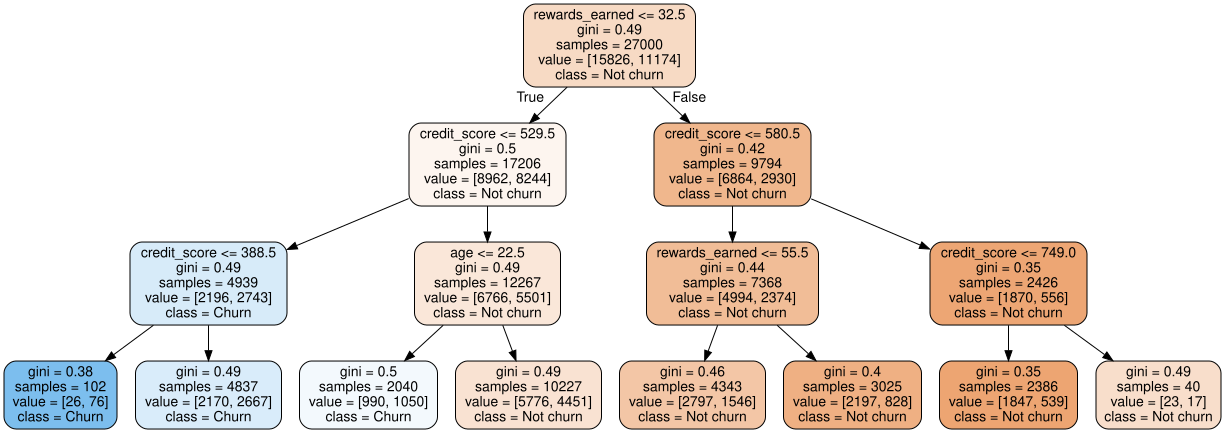

In [86]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_graphviz
from sklearn import tree
from graphviz import Source
from IPython.display import SVG,display

# Creating new column feature_type
score["feature_type"] = np.where(score["features"].isin(num_cols),"Numerical","Categorical")

#top 3 categorical features
features_cat  = score[score["feature_type"] == "Categorical"]["features"][:3].tolist()

#top 3 numerical features
features_num  = score[score["feature_type"] == "Numerical"]["features"][:3].tolist()


#Function attributes
#columns        - selected columns
#maximum_depth  - depth of tree
#criterion_type - ["gini" or "entropy"]
#split_type     - ["best" or "random"]
#Model Performance - True (gives model output)

def plot_decision_tree(columns,maximum_depth,criterion_type,
                       split_type,model_performance = None) :
    
    #separating dependent and in dependent variables
    dtc_x = df_x[columns]
    dtc_y = df_y[tgt_col]
    
    #model
    dt_classifier = DecisionTreeClassifier(max_depth = maximum_depth,
                                           splitter  = split_type,
                                           criterion = criterion_type,
                                          )
    dt_classifier.fit(dtc_x,dtc_y)
    
    #plot decision tree
    graph = Source(tree.export_graphviz(dt_classifier,out_file=None,
                                        rounded=True,proportion = False,
                                        feature_names = columns, 
                                        precision  = 2,
                                        class_names=["Not churn","Churn"],
                                        filled = True                         
                                       )
                  )
                  
    
    #model performance
    if model_performance == True :
        bank_churn_prediction(dt_classifier,
                                 dtc_x,X_test[columns],
                                 dtc_y,Y_test,
                                 columns,"features",threshold_plot = True)
    display(graph)
    
plot_decision_tree(features_num,3,"gini","best")

#### Using top three categorical features

DecisionTreeClassifier(class_weight=None, criterion='entropy', max_depth=3,
            max_features=None, max_leaf_nodes=None,
            min_impurity_decrease=0.0, min_impurity_split=None,
            min_samples_leaf=1, min_samples_split=2,
            min_weight_fraction_leaf=0.0, presort=False, random_state=None,
            splitter='best')
Classification Report : 
               precision    recall  f1-score   support

           0       0.69      0.75      0.72      4733
           1       0.59      0.52      0.55      3367

   micro avg       0.65      0.65      0.65      8100
   macro avg       0.64      0.63      0.63      8100
weighted avg       0.65      0.65      0.65      8100

Accuracy Score :  0.6522222222222223
 Area under curve :  0.6329343334414115 

This is the format of your plot grid:
[ (1,1) x1,y1 ]  [ (1,2) x2,y2 ]
[ (2,1) x3,y3           -      ]



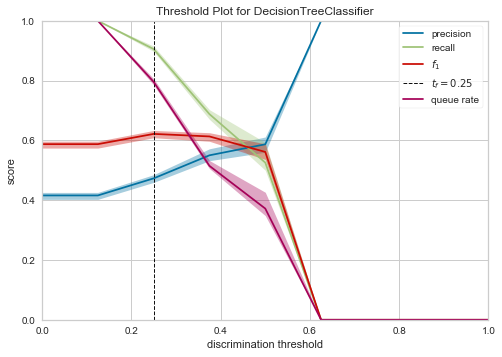

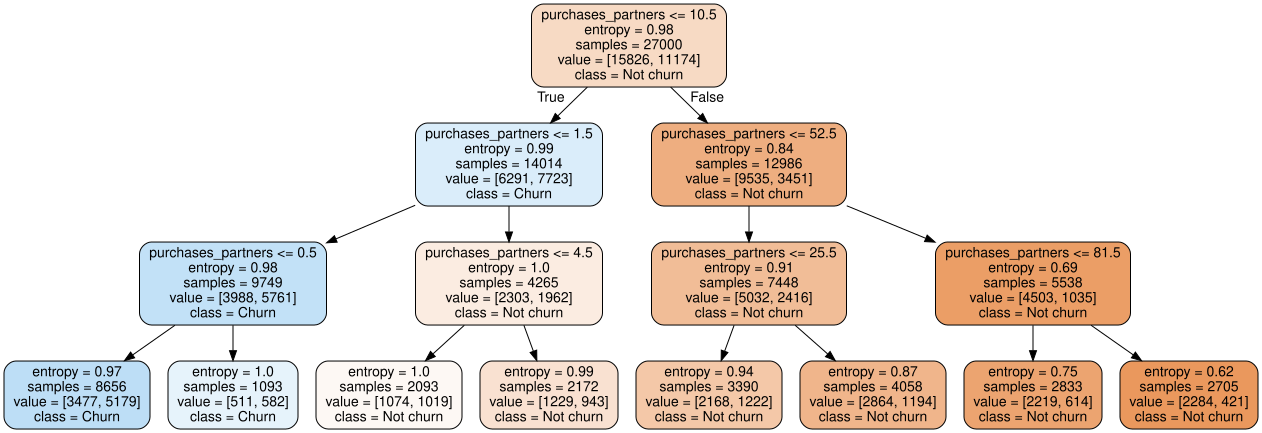

In [87]:
plot_decision_tree(features_cat,3,"entropy","best",model_performance=True)

#### <font color='sky blue'>KNN Classifier</font>

<ul>
<li>Applying KNN algorithm to oversampled data</li>
</ul>

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:3: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=1, n_neighbors=5, p=2,
           weights='uniform')

 Classification report : 
               precision    recall  f1-score   support

           0       0.80      0.73      0.76      4733
           1       0.66      0.74      0.70      3367

   micro avg       0.74      0.74      0.74      8100
   macro avg       0.73      0.74      0.73      8100
weighted avg       0.74      0.74      0.74      8100

Accuracy Score :  0.7354320987654321
Area under curve :  0.7356806857123781


C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages

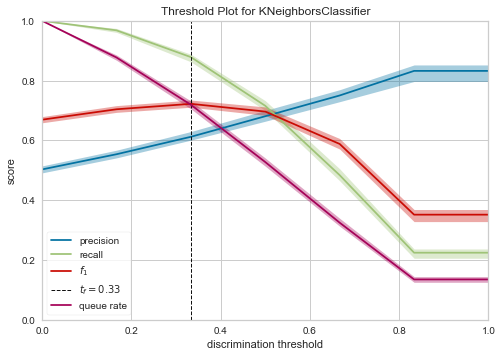

In [88]:
def bank_churn_prediction_alg(algorithm, train_x, test_x, train_y, test_y, threshold_plot=True):
    # model
    algorithm.fit(train_x, train_y)
    predictions = algorithm.predict(test_x)
    probabilities = algorithm.predict_proba(test_x)
    
    print(algorithm)
    print("\n Classification report : \n", classification_report(test_y, predictions))
    print("Accuracy Score : ",accuracy_score(test_y, predictions))
    # confusion matrix
    conf_matrix = confusion_matrix(test_y, predictions)
    # roc_auc_score
    model_roc_auc = roc_auc_score(test_y, predictions)
    print("Area under curve : ",model_roc_auc)
    fpr, tpr, thresholds = roc_curve(test_y, probabilities[:,1])
    
    # plot roc curve
    trace1 = go.Scatter(x = fpr, y = tpr, 
                        name = "Roc" + str(model_roc_auc),
                        line = dict(color = ('rgb(22, 96,197)'), width = 2),
                       )
    trace2 = go.Scatter(x = [0,1], y = [0,1],
                        line = dict(color = ('rgb(205, 12 , 24)'), width = 2, dash = 'dot'))
    
    # plot confusion matrix
    trace3 = go.Heatmap(z = conf_matrix, x = ["Not Churn", "Churn"],
                        y = ["Not Churn", "Churn"],
                        showscale = False, colorscale = "Blues", name = "matrix",
                        xaxis = "x2", yaxis = "y2"
                       )
    
    layout = go.Layout(dict(title="Model Performance",
                            autosize = False, height = 500, width = 800,
                            showlegend = False, plot_bgcolor = "rgb(243, 243, 243)",
                            paper_bgcolor = "rgb(243, 243, 243)",
                            xaxis = dict(title = "false positive rate",
                                         gridcolor = 'rgb(255, 255, 255)',
                                         domain = [0, 0.6],
                                         ticklen = 5, gridwidth = 2),
                            yaxis = dict(title = "true positive rate",
                                         gridcolor = 'rgb(255, 255, 255)',
                                         zerolinewidth = 1,
                                         ticklen = 5, gridwidth = 2),
                            margin = dict(b=200),
                           xaxis2 = dict(domain=[0.7,1], tickangle = 90,
                                         gridcolor = 'rgb(255, 255, 255)'),
                           
                           yaxis2 = dict(anchor = 'x2', gridcolor = 'rgb(255, 255, 255)')
                           )
                      )
    data = [trace1, trace2, trace3]
    fig = go.Figure(data=data, layout=layout)
    
    py.iplot(fig)
    
    if threshold_plot==True:
        visualizer = DiscriminationThreshold(algorithm)
        visualizer.fit(train_x, train_y)
        visualizer.poof()
        
        
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(algorithm='auto', leaf_size=30, metric = 'minkowski',
                           metric_params = None, n_jobs = 1, n_neighbors = 5, p = 2,
                          weights = 'uniform')

bank_churn_prediction_alg(knn, os_smote_X, X_test, os_smote_Y,Y_test, threshold_plot=True)
        

#### <font color = 'sky blue'>Visualizing a decision tree from random forest classifier</font>

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



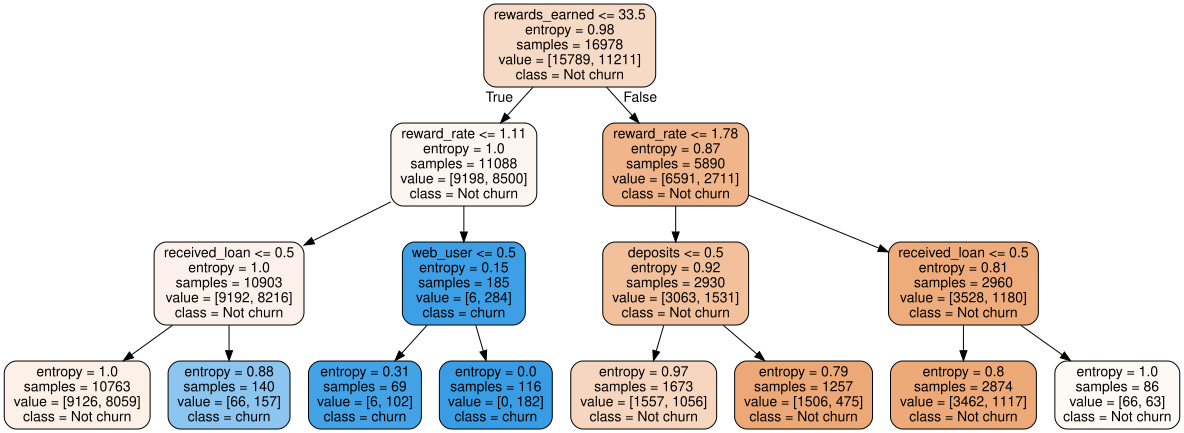

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:3: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



RandomForestClassifier(bootstrap=True, class_weight=None, criterion='entropy',
            max_depth=3, max_features='auto', max_leaf_nodes=None,
            min_impurity_decrease=0.0, min_impurity_split=None,
            min_samples_leaf=1, min_samples_split=2,
            min_weight_fraction_leaf=0.0, n_estimators=100, n_jobs=None,
            oob_score=False, random_state=None, verbose=0,
            warm_start=False)
Classification Report : 
               precision    recall  f1-score   support

           0       0.66      0.84      0.74      4733
           1       0.64      0.39      0.48      3367

   micro avg       0.65      0.65      0.65      8100
   macro avg       0.65      0.61      0.61      8100
weighted avg       0.65      0.65      0.63      8100

Accuracy Score :  0.6535802469135803
 Area under curve :  0.6149813149601867 

This is the format of your plot grid:
[ (1,1) x1,y1 ]  [ (1,2) x2,y2 ]
[ (2,1) x3,y3           -      ]



C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yel

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yellowbrick\classifier\threshold.py:297: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\yel

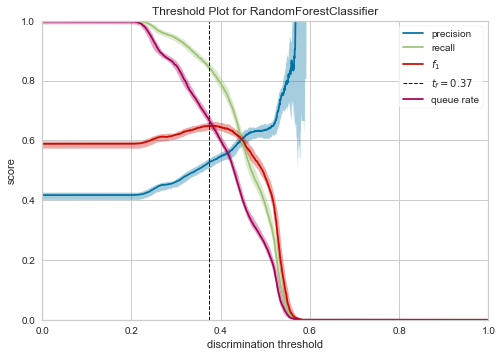

In [89]:
from sklearn.ensemble import RandomForestClassifier

def plot_tree_randomforest(columns, nf_estimators, estimated_tree, maximum_depth,
                           criterion_type, model_performance = None):
    dataframe = bank[columns + tgt_col].copy()
    
    # train and test datasets
    rf_x = dataframe[[i for i in columns if i not in tgt_col]]
    rf_y = dataframe[tgt_col]
    
    # random forest classifier
    rfc = RandomForestClassifier(n_estimators = nf_estimators,
                                 max_depth = maximum_depth,
                                 criterion = criterion_type
                                )
    
    rfc.fit(rf_x, rf_y)
    
    estimated_tree = rfc.estimators_[estimated_tree]
    
    graph = Source(tree.export_graphviz(estimated_tree, out_file=None, 
                                        rounded = True, proportion=False,
                                        feature_names = columns,
                                        precision=2,
                                        class_names=['Not churn','churn'],
                                        filled=True))
    
    display(graph)
    
    # model performance
    if model_performance == True:
        bank_churn_prediction(rfc, rf_x, X_test[columns],
                              rf_y, Y_test, columns, "features", threshold_plot=True)
        

cols1 = [ i for i in X_train.columns if i not in Id_col + tgt_col]
plot_tree_randomforest(cols1, 100, 99, 3 ,"entropy", True)

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



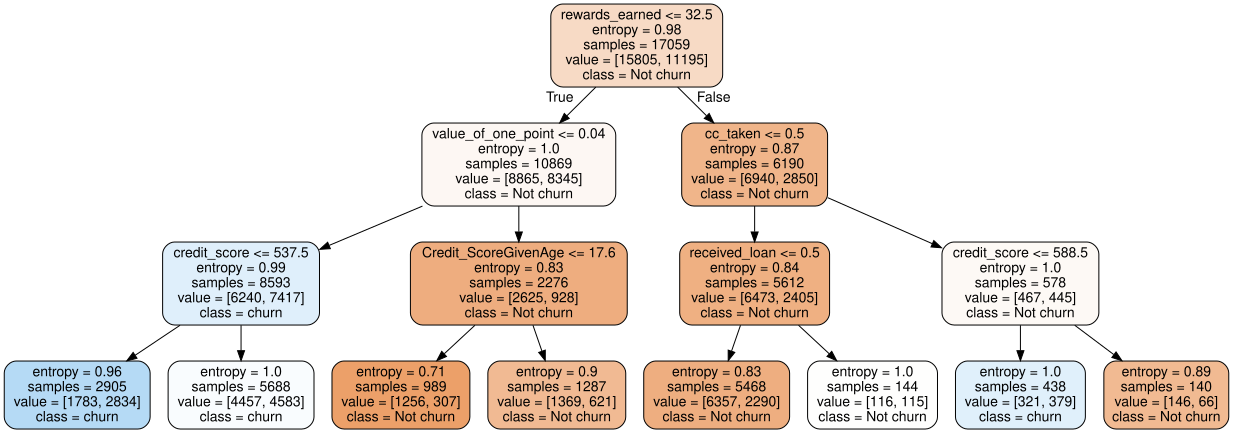

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



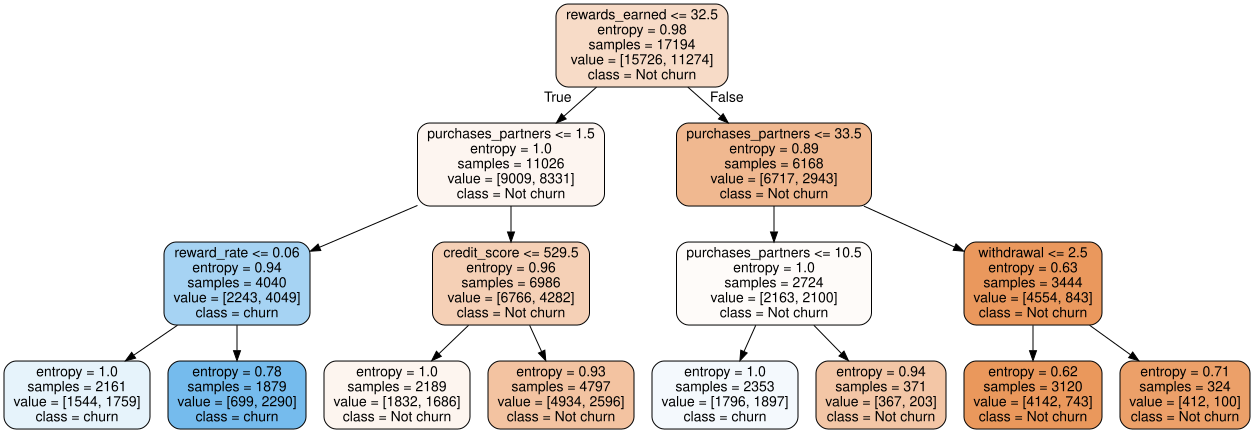

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



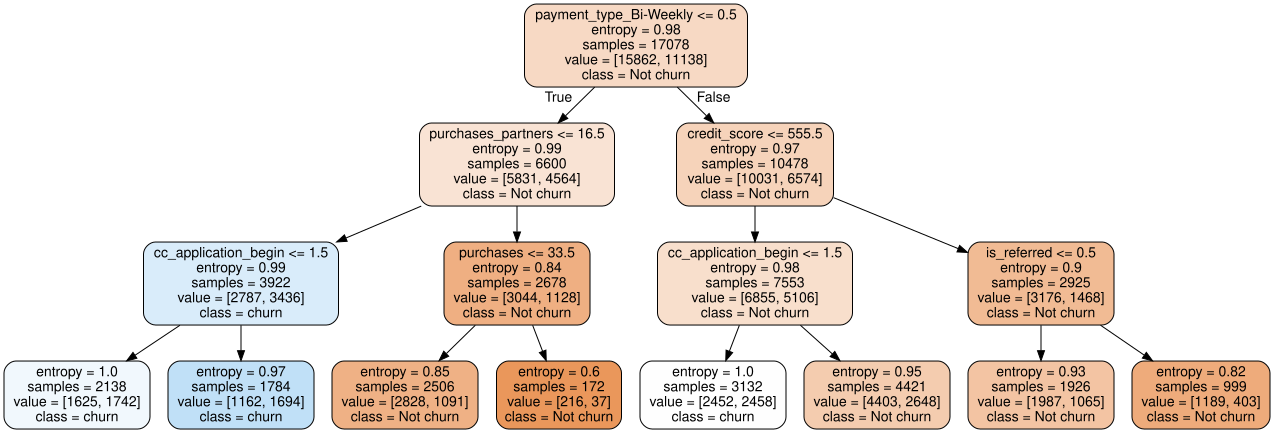

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



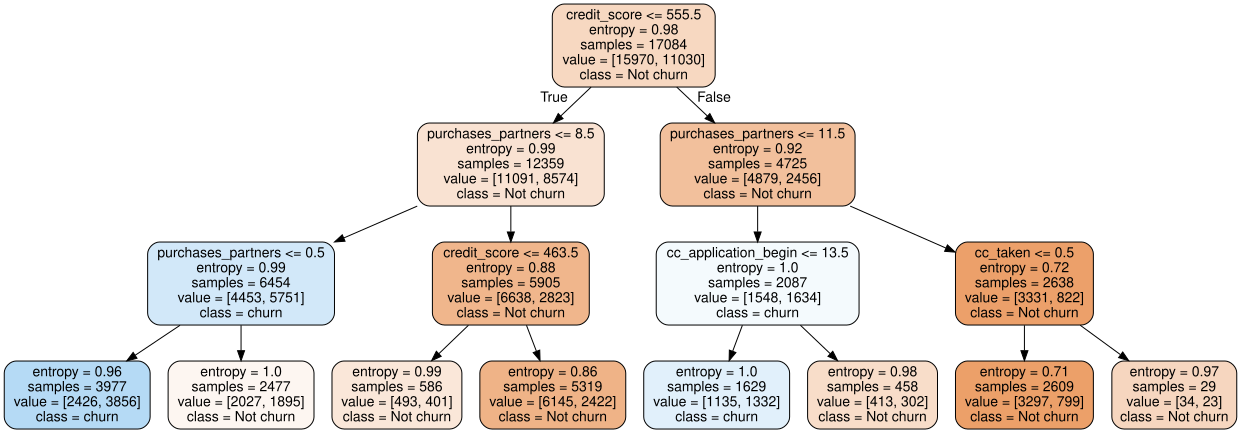

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:17: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



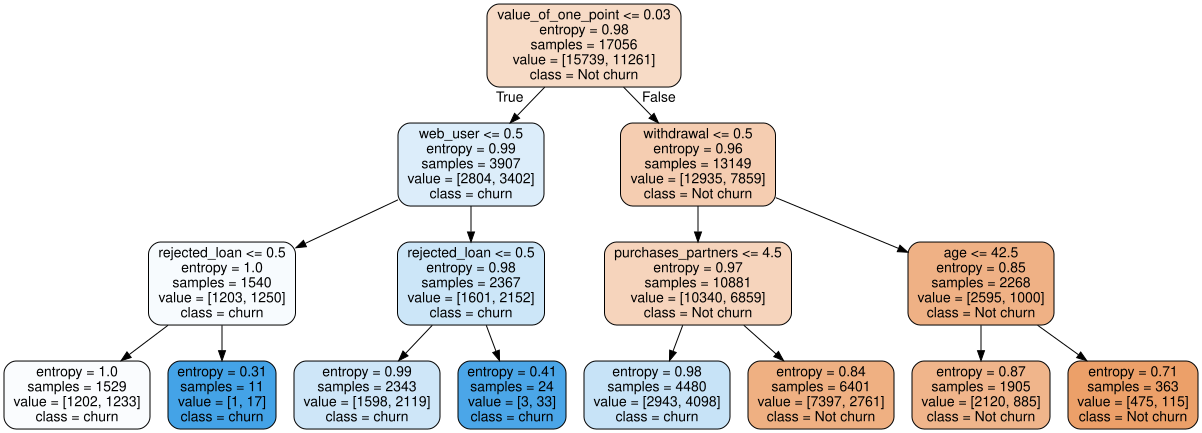

In [90]:
# making 5 trees with randomforest
n = np.arange(0,5).tolist()
cols1 = [i for i in X_train.columns if i not in Id_col + tgt_col]
for i in n:
    plot_tree_randomforest(cols1, 5, i, 3, "entropy",model_performance=False)

#### <font color = 'sky blue'>Gaussian Naive Bayes</font>

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



GaussianNB(priors=None, var_smoothing=1e-09)

 Classification report : 
               precision    recall  f1-score   support

           0       0.74      0.40      0.52      4733
           1       0.49      0.80      0.61      3367

   micro avg       0.57      0.57      0.57      8100
   macro avg       0.61      0.60      0.56      8100
weighted avg       0.64      0.57      0.56      8100

Accuracy Score :  0.5681481481481482
Area under curve :  0.6017514671645244


C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761

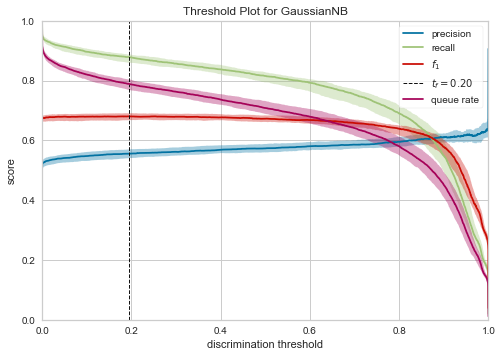

In [91]:
from sklearn.naive_bayes import GaussianNB
gnb  = GaussianNB(priors=None)

bank_churn_prediction_alg(gnb,os_smote_X, X_test, os_smote_Y, Y_test)


### <font color='sky blue'>12. Model Performance </font>

In [92]:
from sklearn.metrics import f1_score

# gives model report in dataframe
def model_report(model, train_x, test_x, train_y, test_y,name):
    model.fit(train_x, train_y)
    predictions = model.predict(test_x)
    accuracy = accuracy_score(test_y, predictions)
    recallscore = recall_score(test_y, predictions)
    precision = precision_score(test_y, predictions)
    roc_auc = roc_auc_score(test_y, predictions)
    f1score = f1_score(test_y, predictions)
    
    df = pd.DataFrame({"Model" : [name],
                       "Accuracy_score" : [accuracy],
                       "Recall_score" : [recallscore],
                       "Precision" : [precision],
                       "f1_score" : [f1score],
                       "Area_under_curve" : [roc_auc]}
                     )
    return df

# outputs for every model
model1 = model_report(logit,X_train,X_test,Y_train, Y_test,"LogReg(Baseline_model)")
model2 = model_report(logit_smote,os_smote_X,X_test,os_smote_Y, Y_test,"LogReg(SMOTE)" )
model3 = model_report(logit_rfe,X_train,X_test,Y_train, Y_test,"LogReg(RFE)" )
dtc = DecisionTreeClassifier(max_depth = 9,
                             random_state=123,
                             splitter = 'best',
                             criterion = 'gini'
                            )
model4 = model_report(dtc,X_train,X_test,Y_train, Y_test,"Decision Tree")
model5 = model_report(knn,os_smote_X,X_test,os_smote_Y,Y_test,"KNN Classifier")
rfc = RandomForestClassifier(n_estimators = 1000, random_state=123, max_depth = 9, criterion = "gini")
model6 = model_report(rfc, X_train, X_test, Y_train, Y_test, "Random Forest Classifier")
model7 = model_report(gnb,os_smote_X, X_test, os_smote_Y, Y_test, "Naive Bayes")


# concat all models
model_performances = pd.concat([model1, model2, model3, model4, model5, model6, model7], axis=0).reset_index()

model_performances = model_performances.drop(columns="index",axis=1)

table = ff.create_table(np.round(model_performances,4))

py.iplot(table)

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\linear_model\logistic.py:433: FutureWarning:

Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\ipykernel_launcher.py:5: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

C:\Users\Dad\Anaconda3\lib\site-packages\sklearn\utils\validation.py:761: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



#### <font color='sky blue'>Compare model metrics</font>

In [93]:
model_performances
def output_trace(metric, color):
    trace = go.Bar(y = model_performances["Model"],
                   x = model_performances[metric],
                   orientation = "h", name = metric,
                   marker = dict(line = dict(width = .7),
                                 color = color)
                  )
    return trace

layout = go.Layout(dict(title = "Model Performances",
                        plot_bgcolor = "rgb(243, 243, 243)",
                        paper_bgcolor = "rgb(243, 243, 243)",
                        xaxis = dict(gridcolor = 'rgb(255, 255, 255)',
                                     title = "metric",
                                     zerolinewidth = 1,
                                     ticklen = 5, gridwidth = 2),
                        yaxis = dict(gridcolor = 'rgb(255, 255, 255)',
                                     zerolinewidth = 1, ticklen = 5,
                                     gridwidth = 2),
                        margin = dict(l = 250),
                        height = 780
                       )
                  )

trace1 = output_trace("Accuracy_score","blue")
trace2 = output_trace("Recall_score","red")
trace3 = output_trace("Precision","green")
trace4 = output_trace("f1_score","lightgrey")

data = [trace1, trace2 , trace3, trace4]
fig = go.Figure(data=data, layout=layout)
py.iplot(fig)